# CS 7 · S02 — GPU Offloading Crossover Point

**Problem statement:** Find the problem size at which GPU execution becomes faster than CPU execution.

**Research question:** At what problem size does GPU offloading become beneficial?

**Objectives (from the case study)**
1. Use **logarithmically increasing** problem sizes.
2. Separate **kernel time** and **end-to-end time**.
3. Identify the **crossover** point.

**Benchmarks:** vector addition (memory-bound), matrix multiplication (compute-bound), 3×3 image blur (stencil / image kernel).
**Tools:** C++ + CUDA, with OpenMP for the CPU baseline. An optional OpenMP *target offload* version is included if `nvc++` is installed.

**Required metrics:** kernel time, end-to-end time, speedup, transfer overhead.
**Expected graphs:** problem size vs time · problem size vs speedup · problem size vs transfer fraction.

### How to run (Kaggle)
1. Right panel → **Session options → Accelerator → GPU T4 ×2** (or P100). **Internet is not required.**
2. *Run All*. The notebook uses GPU 0 only and every CPU/GPU measurement is repeated `TRIALS` times (median reported).
3. When finished, everything is in `/kaggle/working/` → **Output** tab (`s02_results.zip`, `results/*.png`, `results/*.csv`, `results/s02_discussion.md`).

### Definitions used throughout
| Term | Meaning |
|---|---|
| `cpu_serial_ms` | CPU time, 1 thread |
| `cpu_omp_ms` | CPU time, all cores with OpenMP (the **fair CPU baseline**) |
| `kernel_ms` | GPU kernel execution only (CUDA events) |
| `h2d_ms`, `d2h_ms` | Host→Device and Device→Host copy time |
| `e2e_ms` | End-to-end GPU time = `h2d + kernel + d2h` |
| `e2e_alloc_ms` | `e2e` plus `cudaMalloc`/`cudaFree` (wall-clock) |
| Speedup (kernel) | `cpu_omp_ms / kernel_ms` |
| Speedup (end-to-end) | `cpu_omp_ms / e2e_ms` |
| Transfer fraction | `(h2d + d2h) / e2e` |
| **Crossover** | smallest size from which GPU speedup stays > 1 for all larger sizes (log-log interpolated between the two bracketing sizes) |

## 1. Environment check

In [13]:
import subprocess, os, shutil, platform, multiprocessing

def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    return (r.stdout + r.stderr).strip()

os.makedirs("results", exist_ok=True)

# Kaggle gives 2 GPUs: use only GPU 0 so results are reproducible. These env vars are inherited by the benchmark subprocess.
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
NCORES = multiprocessing.cpu_count()
os.environ["OMP_NUM_THREADS"] = str(NCORES)
print("Working dir:", os.getcwd(), "| OMP threads:", NCORES, "| using GPU 0 only")

print("== GPU ==");  print(sh("nvidia-smi --query-gpu=name,memory.total,driver_version,compute_cap --format=csv"))
print("\n== nvcc =="); print(sh("nvcc --version | tail -n 2"))
print("\n== CPU ==");  print(sh("lscpu | grep -E 'Model name|^CPU\\(s\\)|Thread|MHz' "))
print("\nLogical cores:", multiprocessing.cpu_count(), "| Python", platform.python_version())

assert shutil.which("nvcc"), "nvcc not found - enable a GPU runtime / install the CUDA toolkit."
assert "NVIDIA" in sh("nvidia-smi -L") or "GPU" in sh("nvidia-smi -L"), "No NVIDIA GPU detected."

def detect_arch():
    try:
        cc = sh("nvidia-smi --query-gpu=compute_cap --format=csv,noheader").split("\n")[0].strip()
        return "sm_" + cc.replace(".", "")
    except Exception:
        return "sm_75"
ARCH = detect_arch()
print("Compiling for:", ARCH)

# keep a copy of the system info for the report
with open("results/system_info.txt", "w") as f:
    f.write(sh("nvidia-smi --query-gpu=name,memory.total,driver_version,compute_cap --format=csv") + "\n")
    f.write(sh("nvcc --version | tail -n 2") + "\n")
    f.write(sh("lscpu | grep -E 'Model name|^CPU\\(s\\)'") + "\n")
    f.write(f"OMP threads used: {NCORES}\nGPU used: device 0 only\n")

Working dir: /kaggle/working | OMP threads: 4 | using GPU 0 only
== GPU ==
name, memory.total [MiB], driver_version, compute_cap
Tesla T4, 15360 MiB, 580.178.04, 7.5
Tesla T4, 15360 MiB, 580.178.04, 7.5

== nvcc ==
Cuda compilation tools, release 12.8, V12.8.93
Build cuda_12.8.r12.8/compiler.35583870_0

== CPU ==
CPU(s):                                  4
Model name:                              Intel(R) Xeon(R) CPU @ 2.00GHz
Thread(s) per core:                      2

Logical cores: 4 | Python 3.13.15
Compiling for: sm_75


## 2. Benchmark program (C++ / CUDA / OpenMP)

One executable runs a sweep of **geometrically spaced sizes** (×√2 per step → two points per octave, i.e. logarithmic spacing) for one benchmark and prints CSV.

For every size it measures (median of several repetitions, after a warm-up):
- CPU serial and CPU OpenMP time,
- GPU `cudaMalloc/Free`, H2D copy, kernel, D2H copy (CUDA events),
- numerical error of the GPU result versus the CPU result (correctness check).

Number of repetitions is chosen automatically (many for tiny sizes to beat timer noise, few for huge sizes).
Host memory is ordinary **pageable** memory – the realistic default for "naive" offloading.

In [14]:
%%writefile s02_bench.cu
// S02 - GPU offloading crossover benchmark (CUDA + OpenMP)
#include <cstdio>
#include <cstdlib>
#include <cmath>
#include <vector>
#include <algorithm>
#include <string>
#include <omp.h>
#include <cuda_runtime.h>

#define CK(x) do { cudaError_t e_ = (x); if (e_ != cudaSuccess) { \
    fprintf(stderr, "CUDA error '%s' at %s:%d\n", cudaGetErrorString(e_), __FILE__, __LINE__); exit(1); } } while (0)

// ------------------------------------------------------------- GPU kernels
__global__ void k_vecadd(const float* a, const float* b, float* c, size_t n) {
    size_t i = (size_t)blockIdx.x * blockDim.x + threadIdx.x;
    if (i < n) c[i] = a[i] + b[i];
}

#define TS 16
__global__ void k_matmul(const float* A, const float* B, float* C, int n) {   // tiled shared-memory matmul
    __shared__ float As[TS][TS], Bs[TS][TS];
    int r = blockIdx.y * TS + threadIdx.y, c = blockIdx.x * TS + threadIdx.x;
    float s = 0.f;
    for (int t = 0; t < (n + TS - 1) / TS; t++) {
        int ac = t * TS + threadIdx.x, br = t * TS + threadIdx.y;
        As[threadIdx.y][threadIdx.x] = (r < n && ac < n) ? A[(size_t)r * n + ac] : 0.f;
        Bs[threadIdx.y][threadIdx.x] = (br < n && c < n) ? B[(size_t)br * n + c] : 0.f;
        __syncthreads();
        for (int k = 0; k < TS; k++) s += As[threadIdx.y][k] * Bs[k][threadIdx.x];
        __syncthreads();
    }
    if (r < n && c < n) C[(size_t)r * n + c] = s;
}

__global__ void k_blur(const float* in, float* out, int w) {                   // 3x3 box blur, clamped edges
    int x = blockIdx.x * blockDim.x + threadIdx.x, y = blockIdx.y * blockDim.y + threadIdx.y;
    if (x >= w || y >= w) return;
    float s = 0.f;
    for (int dy = -1; dy <= 1; dy++)
        for (int dx = -1; dx <= 1; dx++) {
            int xx = min(max(x + dx, 0), w - 1), yy = min(max(y + dy, 0), w - 1);
            s += in[(size_t)yy * w + xx];
        }
    out[(size_t)y * w + x] = s / 9.f;
}

// ------------------------------------------------------------- CPU versions (OpenMP, th=1 -> serial)
static void cpu_vecadd(const float* a, const float* b, float* c, long long n, int th) {
    #pragma omp parallel for num_threads(th)
    for (long long i = 0; i < n; i++) c[i] = a[i] + b[i];
}
static void cpu_matmul(const float* A, const float* B, float* C, int n, int th) {   // i-k-j order (cache friendly)
    #pragma omp parallel for num_threads(th)
    for (int i = 0; i < n; i++) {
        float* Ci = C + (size_t)i * n;
        for (int j = 0; j < n; j++) Ci[j] = 0.f;
        for (int k = 0; k < n; k++) {
            float a = A[(size_t)i * n + k];
            const float* Bk = B + (size_t)k * n;
            for (int j = 0; j < n; j++) Ci[j] += a * Bk[j];
        }
    }
}
static void cpu_blur(const float* in, float* out, int w, int th) {
    #pragma omp parallel for num_threads(th)
    for (int y = 0; y < w; y++)
        for (int x = 0; x < w; x++) {
            float s = 0.f;
            for (int dy = -1; dy <= 1; dy++)
                for (int dx = -1; dx <= 1; dx++) {
                    int xx = std::min(std::max(x + dx, 0), w - 1), yy = std::min(std::max(y + dy, 0), w - 1);
                    s += in[(size_t)yy * w + xx];
                }
            out[(size_t)y * w + x] = s / 9.f;
        }
}

static double median(std::vector<double>& v) { std::sort(v.begin(), v.end()); return v[v.size() / 2]; }

struct Row { double cpu1, cpuN, alloc, h2d, kern, d2h, e2e, e2ea, err; double bh, bd; };

static Row run(int kind, long long size, int maxth) {
    size_t nin = (kind == 2) ? 1 : 2;
    size_t in_el, out_el; double work;
    if (kind == 0)      { in_el = out_el = (size_t)size;        work = (double)size; }
    else if (kind == 1) { in_el = out_el = (size_t)size * size; work = 2.0 * size * size * size; }
    else                { in_el = out_el = (size_t)size * size; work = 9.0 * size * size; }
    int reps = std::max(3, std::min(200, (int)(2e8 / work)));

    std::vector<float> h_in[2], h_out(out_el), ref(out_el);
    unsigned s = 12345u;
    for (size_t k = 0; k < nin; k++) {
        h_in[k].resize(in_el);
        for (size_t i = 0; i < in_el; i++) { s = s * 1664525u + 1013904223u; h_in[k][i] = (s >> 8) / 16777216.0f; }
    }
    auto cpu = [&](float* out, int th) {
        if (kind == 0)      cpu_vecadd(h_in[0].data(), h_in[1].data(), out, size, th);
        else if (kind == 1) cpu_matmul(h_in[0].data(), h_in[1].data(), out, (int)size, th);
        else                cpu_blur(h_in[0].data(), out, (int)size, th);
    };

    // ---------------- CPU timing
    std::vector<double> t1, tN;
    cpu(ref.data(), maxth);                                   // warm-up + reference result
    for (int r = 0; r < reps; r++) { double t = omp_get_wtime(); cpu(h_out.data(), 1);     t1.push_back((omp_get_wtime() - t) * 1e3); }
    for (int r = 0; r < reps; r++) { double t = omp_get_wtime(); cpu(h_out.data(), maxth); tN.push_back((omp_get_wtime() - t) * 1e3); }

    // ---------------- GPU timing
    cudaEvent_t e0, e1, e2, e3;
    CK(cudaEventCreate(&e0)); CK(cudaEventCreate(&e1)); CK(cudaEventCreate(&e2)); CK(cudaEventCreate(&e3));
    std::vector<double> va, vh, vk, vd, ve, vea;
    for (int it = -1; it < reps; it++) {                      // it = -1 is a warm-up
        double w0 = omp_get_wtime();
        float *d_in[2] = {nullptr, nullptr}, *d_out = nullptr;
        for (size_t k = 0; k < nin; k++) CK(cudaMalloc(&d_in[k], in_el * sizeof(float)));
        CK(cudaMalloc(&d_out, out_el * sizeof(float)));
        double w1 = omp_get_wtime();

        CK(cudaEventRecord(e0));
        for (size_t k = 0; k < nin; k++) CK(cudaMemcpy(d_in[k], h_in[k].data(), in_el * sizeof(float), cudaMemcpyHostToDevice));
        CK(cudaEventRecord(e1));
        if (kind == 0) {
            int th = 256; size_t bl = ((size_t)size + th - 1) / th;
            k_vecadd<<<(unsigned)bl, th>>>(d_in[0], d_in[1], d_out, (size_t)size);
        } else {
            dim3 b(16, 16), g((size + 15) / 16, (size + 15) / 16);
            if (kind == 1) k_matmul<<<g, b>>>(d_in[0], d_in[1], d_out, (int)size);
            else           k_blur<<<g, b>>>(d_in[0], d_out, (int)size);
        }
        CK(cudaGetLastError());
        CK(cudaEventRecord(e2));
        CK(cudaMemcpy(h_out.data(), d_out, out_el * sizeof(float), cudaMemcpyDeviceToHost));
        CK(cudaEventRecord(e3)); CK(cudaEventSynchronize(e3));

        for (size_t k = 0; k < nin; k++) CK(cudaFree(d_in[k]));
        CK(cudaFree(d_out));
        double w2 = omp_get_wtime();
        if (it < 0) continue;

        float a, b2, c, d;
        CK(cudaEventElapsedTime(&a,  e0, e1)); CK(cudaEventElapsedTime(&b2, e1, e2)); CK(cudaEventElapsedTime(&c, e2, e3));
        (void)d;
        vh.push_back(a); vk.push_back(b2); vd.push_back(c); ve.push_back((double)a + b2 + c);
        va.push_back((w1 - w0) * 1e3);
        vea.push_back((w2 - w0) * 1e3);
    }
    CK(cudaEventDestroy(e0)); CK(cudaEventDestroy(e1)); CK(cudaEventDestroy(e2)); CK(cudaEventDestroy(e3));

    // ---------------- correctness
    double mx = 0, mr = 1e-6;
    for (size_t i = 0; i < out_el; i++) { mx = std::max(mx, (double)std::fabs(h_out[i] - ref[i])); mr = std::max(mr, (double)std::fabs(ref[i])); }

    Row r;
    r.cpu1 = median(t1); r.cpuN = median(tN); r.alloc = median(va); r.h2d = median(vh);
    r.kern = median(vk); r.d2h = median(vd); r.e2e = median(ve); r.e2ea = median(vea);
    r.err = mx / mr; r.bh = (double)nin * in_el * sizeof(float); r.bd = (double)out_el * sizeof(float);
    return r;
}

int main(int argc, char** argv) {
    if (argc < 2) { fprintf(stderr, "usage: %s vecadd|matmul|blur [quick]\n", argv[0]); return 1; }
    std::string name = argv[1];
    bool quick = argc > 2 && std::string(argv[2]) == "quick";
    int kind = name == "vecadd" ? 0 : name == "matmul" ? 1 : name == "blur" ? 2 : -1;
    if (kind < 0) { fprintf(stderr, "unknown benchmark\n"); return 1; }

    double lo, hi;
    if (kind == 0)      { lo = 256; hi = quick ? (double)(1 << 22) : (double)(1 << 26); }
    else if (kind == 1) { lo = 8;   hi = quick ? 512  : 2048; }
    else                { lo = 16;  hi = quick ? 1024 : 8192; }
    double f = quick ? 2.0 : std::sqrt(2.0);                  // geometric (logarithmic) spacing

    int maxth = omp_get_max_threads();
    CK(cudaFree(0));                                          // force CUDA context creation before timing
    printf("benchmark,size,cpu_serial_ms,cpu_omp_ms,alloc_ms,h2d_ms,kernel_ms,d2h_ms,e2e_ms,e2e_alloc_ms,bytes_h2d,bytes_d2h,max_rel_err\n");
    long long last = 0;
    for (double sz = lo; sz <= hi * 1.0001; sz *= f) {
        long long n = llround(sz);
        if (n == last) continue;
        last = n;
        Row r = run(kind, n, maxth);
        printf("%s,%lld,%.6f,%.6f,%.6f,%.6f,%.6f,%.6f,%.6f,%.6f,%.0f,%.0f,%.3e\n", name.c_str(), n,
               r.cpu1, r.cpuN, r.alloc, r.h2d, r.kern, r.d2h, r.e2e, r.e2ea, r.bh, r.bd, r.err);
        fflush(stdout);
        fprintf(stderr, "[%s] size=%lld  cpu_omp=%.3f ms  kernel=%.3f ms  e2e=%.3f ms  err=%.1e\n", name.c_str(), n, r.cpuN, r.kern, r.e2e, r.err);
    }
    return 0;
}

Overwriting s02_bench.cu


## 3. Compile

In [15]:
cmd = f"nvcc -O3 -std=c++14 -arch={ARCH} -Xcompiler -fopenmp s02_bench.cu -o s02_bench"
print(cmd)
out = sh(cmd)
print(out if out else "Compiled OK")
assert os.path.exists("s02_bench"), "Compilation failed - read the error above."

nvcc -O3 -std=c++14 -arch=sm_75 -Xcompiler -fopenmp s02_bench.cu -o s02_bench
Compiled OK


## 4. Run the experiments

`QUICK = True` → fast smoke test (sizes doubled each step, smaller maximum).
`QUICK = False` → real data. With `TRIALS = 3` the whole sweep is repeated 3 times and the **median across trials** is reported per size (this removes one-off noise such as GPU clock ramp-up or a noisy neighbour on the shared Kaggle CPU). Set `TRIALS = 1` if you are short of time.


In [16]:
import io, time, threading
import pandas as pd

QUICK  = False           # <-- True = fast smoke test
TRIALS = 3               # <-- sweeps repeated; median across trials is reported
BENCHMARKS = ["vecadd", "matmul", "blur"]

def run_benchmark(name):
    args = ["./s02_bench", name] + (["quick"] if QUICK else [])
    p = subprocess.Popen(args, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)
    err_lines = []
    def pump():
        for line in p.stderr:
            err_lines.append(line); print(line, end="")
    th = threading.Thread(target=pump); th.start()
    out = p.stdout.read(); p.wait(); th.join()
    if p.returncode != 0:
        raise RuntimeError("benchmark failed:\n" + "".join(err_lines))
    return pd.read_csv(io.StringIO(out))

t0 = time.time()
trial_frames = []
for tr in range(TRIALS):
    print(f"\n########## TRIAL {tr+1}/{TRIALS} ##########")
    f = pd.concat([run_benchmark(b) for b in BENCHMARKS], ignore_index=True)
    f["trial"] = tr
    trial_frames.append(f)
all_trials = pd.concat(trial_frames, ignore_index=True)
all_trials.to_csv("results/s02_cuda_results_all_trials.csv", index=False)

# ---- aggregate: median over trials for timings, max for error, spread = (max-min)/median as a noise indicator
TIME_COLS = ["cpu_serial_ms","cpu_omp_ms","alloc_ms","h2d_ms","kernel_ms","d2h_ms","e2e_ms","e2e_alloc_ms"]
g = all_trials.groupby(["benchmark","size"], sort=False)
raw = g[TIME_COLS].median()
raw["bytes_h2d"]   = g["bytes_h2d"].first()
raw["bytes_d2h"]   = g["bytes_d2h"].first()
raw["max_rel_err"] = g["max_rel_err"].max()
for c in ["cpu_omp_ms", "kernel_ms", "e2e_ms"]:
    raw[c.replace("_ms", "_spread")] = (g[c].max() - g[c].min()) / g[c].median()
raw = raw.reset_index()
raw.to_csv("results/s02_cuda_results.csv", index=False)
print(f"\nDone in {time.time()-t0:.0f}s -> results/s02_cuda_results.csv  ({len(raw)} rows, median of {TRIALS} trials)")
raw.head()



########## TRIAL 1/3 ##########
[vecadd] size=256  cpu_omp=0.003 ms  kernel=0.010 ms  e2e=0.043 ms  err=0.0e+00
[vecadd] size=362  cpu_omp=0.003 ms  kernel=0.010 ms  e2e=0.043 ms  err=0.0e+00
[vecadd] size=512  cpu_omp=0.002 ms  kernel=0.010 ms  e2e=0.042 ms  err=0.0e+00
[vecadd] size=724  cpu_omp=0.003 ms  kernel=0.010 ms  e2e=0.045 ms  err=0.0e+00
[vecadd] size=1024  cpu_omp=0.003 ms  kernel=0.010 ms  e2e=0.045 ms  err=0.0e+00
[vecadd] size=1448  cpu_omp=0.003 ms  kernel=0.010 ms  e2e=0.047 ms  err=0.0e+00
[vecadd] size=2048  cpu_omp=0.003 ms  kernel=0.010 ms  e2e=0.048 ms  err=0.0e+00
[vecadd] size=2896  cpu_omp=0.003 ms  kernel=0.008 ms  e2e=0.050 ms  err=0.0e+00
[vecadd] size=4096  cpu_omp=0.003 ms  kernel=0.009 ms  e2e=0.056 ms  err=0.0e+00
[vecadd] size=5793  cpu_omp=0.003 ms  kernel=0.008 ms  e2e=0.063 ms  err=0.0e+00
[vecadd] size=8192  cpu_omp=0.004 ms  kernel=0.007 ms  e2e=0.072 ms  err=0.0e+00
[vecadd] size=11585  cpu_omp=0.003 ms  kernel=0.006 ms  e2e=0.089 ms  err=0.0e+0

,benchmark,size,cpu_serial_ms,cpu_omp_ms,alloc_ms,h2d_ms,kernel_ms,d2h_ms,e2e_ms,e2e_alloc_ms,bytes_h2d,bytes_d2h,max_rel_err,cpu_omp_spread,kernel_spread,e2e_spread
0,vecadd,256,0.001308,0.002872,0.102434,0.017664,0.010240,0.012480,0.040672,0.247020,2048,1024,0.0,0.040738,0.109375,0.079465
1,vecadd,362,0.001360,0.002675,0.101555,0.017888,0.009824,0.013152,0.040864,0.244779,2896,1448,0.0,0.206355,0.019544,0.061081
2,vecadd,512,0.001368,0.002430,0.099329,0.018240,0.009376,0.012672,0.039872,0.231660,4096,2048,0.0,0.102881,0.119454,0.058587
3,vecadd,724,0.001443,0.002605,0.102902,0.019104,0.009696,0.013824,0.042624,0.254839,5792,2896,0.0,0.032630,0.095710,0.087838
4,vecadd,1024,0.001454,0.002700,0.101886,0.019360,0.010208,0.013824,0.043232,0.253577,8192,4096,0.0,0.083704,0.050157,0.034789


## 5. (Optional) OpenMP *target offload* version

The case study lists **CUDA/OpenMP offload**. If the NVIDIA HPC compiler (`nvc++`) is installed, this cell compiles and runs the same sweep using `#pragma omp target` for vector add and matrix multiply. If `nvc++` is not available (the default on Colab) the cell is skipped and the rest of the notebook works with the CUDA results alone.

In [17]:
%%writefile s02_omp_offload.cpp
// S02 - OpenMP target-offload version (vecadd + matmul).  Build: nvc++ -O3 -mp=gpu s02_omp_offload.cpp
#include <cstdio>
#include <cstdlib>
#include <cmath>
#include <vector>
#include <algorithm>
#include <string>
#include <omp.h>

static double median(std::vector<double>& v) { std::sort(v.begin(), v.end()); return v[v.size() / 2]; }

static void cpu_vecadd(const float* a, const float* b, float* c, long long n, int th) {
    #pragma omp parallel for num_threads(th)
    for (long long i = 0; i < n; i++) c[i] = a[i] + b[i];
}
static void cpu_matmul(const float* A, const float* B, float* C, int n, int th) {
    #pragma omp parallel for num_threads(th)
    for (int i = 0; i < n; i++) {
        for (int j = 0; j < n; j++) C[(size_t)i * n + j] = 0.f;
        for (int k = 0; k < n; k++) { float a = A[(size_t)i * n + k];
            for (int j = 0; j < n; j++) C[(size_t)i * n + j] += a * B[(size_t)k * n + j]; }
    }
}

int main(int argc, char** argv) {
    std::string name = argc > 1 ? argv[1] : "vecadd";
    bool quick = argc > 2 && std::string(argv[2]) == "quick";
    int kind = name == "vecadd" ? 0 : 1;
    double lo = kind == 0 ? 256 : 8, hi = kind == 0 ? (quick ? (double)(1 << 22) : (double)(1 << 26)) : (quick ? 512 : 2048);
    double f = quick ? 2.0 : std::sqrt(2.0);
    int maxth = omp_get_max_threads();
    printf("benchmark,size,cpu_serial_ms,cpu_omp_ms,alloc_ms,h2d_ms,kernel_ms,d2h_ms,e2e_ms,e2e_alloc_ms,bytes_h2d,bytes_d2h,max_rel_err\n");
    long long last = 0;
    for (double sz = lo; sz <= hi * 1.0001; sz *= f) {
        long long n = llround(sz); if (n == last) continue; last = n;
        size_t el = kind == 0 ? (size_t)n : (size_t)n * n;
        double work = kind == 0 ? (double)n : 2.0 * n * n * n;
        int reps = std::max(3, std::min(100, (int)(2e8 / work)));
        std::vector<float> A(el), B(el), C(el), R(el);
        unsigned s = 777u;
        for (size_t i = 0; i < el; i++) { s = s * 1664525u + 1013904223u; A[i] = (s >> 8) / 16777216.0f; s = s * 1664525u + 1013904223u; B[i] = (s >> 8) / 16777216.0f; }
        float *a = A.data(), *b = B.data(), *c = C.data();
        auto cpu = [&](float* out, int th) { if (kind == 0) cpu_vecadd(a, b, out, n, th); else cpu_matmul(a, b, out, (int)n, th); };
        std::vector<double> t1, tN, vh, vk, vd, ve;
        cpu(R.data(), maxth);
        for (int r = 0; r < reps; r++) { double t = omp_get_wtime(); cpu(c, 1);     t1.push_back((omp_get_wtime() - t) * 1e3); }
        for (int r = 0; r < reps; r++) { double t = omp_get_wtime(); cpu(c, maxth); tN.push_back((omp_get_wtime() - t) * 1e3); }
        for (int it = -1; it < reps; it++) {
            double w0 = omp_get_wtime();
            #pragma omp target enter data map(to: a[0:el], b[0:el]) map(alloc: c[0:el])
            double w1 = omp_get_wtime();
            if (kind == 0) {
                #pragma omp target teams distribute parallel for
                for (long long i = 0; i < n; i++) c[i] = a[i] + b[i];
            } else {
                int N = (int)n;
                #pragma omp target teams distribute parallel for collapse(2)
                for (int i = 0; i < N; i++)
                    for (int j = 0; j < N; j++) { float acc = 0.f; for (int k = 0; k < N; k++) acc += a[(size_t)i * N + k] * b[(size_t)k * N + j]; c[(size_t)i * N + j] = acc; }
            }
            double w2 = omp_get_wtime();
            #pragma omp target exit data map(from: c[0:el]) map(delete: a[0:el], b[0:el])
            double w3 = omp_get_wtime();
            if (it < 0) continue;
            vh.push_back((w1 - w0) * 1e3); vk.push_back((w2 - w1) * 1e3); vd.push_back((w3 - w2) * 1e3); ve.push_back((w3 - w0) * 1e3);
        }
        double mx = 0, mr = 1e-6;
        for (size_t i = 0; i < el; i++) { mx = std::max(mx, (double)std::fabs(C[i] - R[i])); mr = std::max(mr, (double)std::fabs(R[i])); }
        double e2e = median(ve);
        printf("omp_%s,%lld,%.6f,%.6f,0,%.6f,%.6f,%.6f,%.6f,%.6f,%.0f,%.0f,%.3e\n", name.c_str(), n, median(t1), median(tN),
               median(vh), median(vk), median(vd), e2e, e2e, 2.0 * el * 4, (double)el * 4, mx / mr);
        fflush(stdout);
        fprintf(stderr, "[omp_%s] size=%lld kernel=%.3f ms e2e=%.3f ms\n", name.c_str(), n, median(vk), e2e);
    }
    return 0;
}

Overwriting s02_omp_offload.cpp


In [27]:
!which nvc++
!which nvcc
!which g++
!g++ --version

/usr/local/cuda/bin/nvcc
/usr/bin/g++
g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
Copyright (C) 2023 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.



In [18]:
OFFLOAD_OK = False
if shutil.which("nvc++"):
    out = sh("nvc++ -O3 -mp=gpu s02_omp_offload.cpp -o s02_omp_offload")
    print(out if out else "nvc++ compile OK")
    if os.path.exists("s02_omp_offload"):
        frames = []
        for b in ["vecadd", "matmul"]:
            r = subprocess.run(["./s02_omp_offload", b] + (["quick"] if QUICK else []), capture_output=True, text=True)
            frames.append(pd.read_csv(io.StringIO(r.stdout)))
        pd.concat(frames, ignore_index=True).to_csv("results/s02_ompoffload_results.csv", index=False)
        OFFLOAD_OK = True
        print("OpenMP offload results saved.")
else:
    print("nvc++ not found -> skipping the OpenMP target-offload experiment (CUDA results are used for the analysis).")

nvc++ not found -> skipping the OpenMP target-offload experiment (CUDA results are used for the analysis).


## 6. Load data and compute derived metrics

In [19]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

df_raw = pd.read_csv("results/s02_cuda_results.csv")

ELEMENTS = {"vecadd": lambda s: s, "matmul": lambda s: s ** 2, "blur": lambda s: s ** 2,
            "omp_vecadd": lambda s: s, "omp_matmul": lambda s: s ** 2}
XLABEL = {"vecadd": "Vector length N (elements)", "matmul": "Matrix dimension n  (n×n matrices)", "blur": "Image side w  (w×w pixels)",
          "omp_vecadd": "Vector length N (elements)", "omp_matmul": "Matrix dimension n  (n×n matrices)"}
TITLE = {"vecadd": "Vector addition", "matmul": "Matrix multiplication", "blur": "3×3 image blur",
         "omp_vecadd": "Vector addition (OpenMP offload)", "omp_matmul": "Matrix multiplication (OpenMP offload)"}

def add_metrics(d):
    d = d.copy().sort_values(["benchmark", "size"]).reset_index(drop=True)
    d["elements"]            = [ELEMENTS[b](s) for b, s in zip(d.benchmark, d["size"])]
    d["transfer_ms"]         = d.h2d_ms + d.d2h_ms
    d["transfer_fraction"]   = d.transfer_ms / d.e2e_ms
    d["kernel_fraction"]     = d.kernel_ms / d.e2e_ms
    d["speedup_kernel_omp"]  = d.cpu_omp_ms    / d.kernel_ms
    d["speedup_e2e_omp"]     = d.cpu_omp_ms    / d.e2e_ms
    d["speedup_kernel_ser"]  = d.cpu_serial_ms / d.kernel_ms
    d["speedup_e2e_ser"]     = d.cpu_serial_ms / d.e2e_ms
    d["speedup_e2e_alloc_omp"] = d.cpu_omp_ms  / d.e2e_alloc_ms
    d["h2d_GBps"]            = d.bytes_h2d / (d.h2d_ms * 1e-3) / 1e9
    d["d2h_GBps"]            = d.bytes_d2h / (d.d2h_ms * 1e-3) / 1e9
    return d

df = add_metrics(df_raw)

print("Correctness check (max relative error GPU vs CPU) per benchmark:")
print(df.groupby("benchmark").max_rel_err.max().to_string())
assert (df.max_rel_err < 1e-3).all(), "GPU result differs from CPU result - investigate before trusting timings."
df.to_csv("results/s02_cuda_results_with_metrics.csv", index=False)
if "e2e_spread" in df.columns:
    print("\nRun-to-run noise across trials, median of (max-min)/median for end-to-end time (small = trustworthy):")
    print(df.groupby("benchmark")[["cpu_omp_spread", "kernel_spread", "e2e_spread"]].median().round(3).to_string())
df[["benchmark","size","cpu_serial_ms","cpu_omp_ms","kernel_ms","e2e_ms","speedup_kernel_omp","speedup_e2e_omp","transfer_fraction"]].round(4).head(12)

Correctness check (max relative error GPU vs CPU) per benchmark:
benchmark
blur      0.000000e+00
matmul    3.155000e-07
vecadd    0.000000e+00

Run-to-run noise across trials, median of (max-min)/median for end-to-end time (small = trustworthy):
           cpu_omp_spread  kernel_spread  e2e_spread
benchmark                                           
blur                0.044          0.051       0.035
matmul              0.061          0.070       0.046
vecadd              0.051          0.073       0.054


,benchmark,size,cpu_serial_ms,cpu_omp_ms,kernel_ms,e2e_ms,speedup_kernel_omp,speedup_e2e_omp,transfer_fraction
0,blur,16,0.0054,0.0038,0.0100,0.0336,0.3818,0.1132,0.7197
1,blur,23,0.0097,0.0051,0.0102,0.0357,0.4978,0.1417,0.7126
2,blur,32,0.0195,0.0081,0.0102,0.0356,0.7908,0.2268,0.7302
3,blur,45,0.0334,0.0124,0.0090,0.0383,1.3795,0.3253,0.7542
4,blur,64,0.0686,0.0234,0.0082,0.0412,2.8539,0.5668,0.8099
5,blur,91,0.1333,0.0452,0.0063,0.0529,7.1319,0.8538,0.8495
6,blur,128,0.1783,0.0905,0.0068,0.0760,13.4042,1.1914,0.9086
7,blur,181,0.3652,0.1792,0.0110,0.1151,16.2274,1.5560,0.8891
8,blur,256,0.7349,0.3596,0.0131,0.1921,27.4720,1.8720,0.9277
9,blur,362,1.4460,0.7360,0.0186,0.3518,39.5165,2.0917,0.9260


## 7. Crossover detection

The crossover is defined as the smallest size **from which the GPU is faster for every larger size tested** (this ignores noisy single-point dips). The exact crossover is estimated by linear interpolation of `log(speedup)` against `log(size)` between the last size where the GPU lost and the first where it won.

In [20]:
def crossover(sizes, speedup):
    """returns (first_size_faster, interpolated_crossover, status)"""
    x = np.asarray(sizes, float); s = np.asarray(speedup, float)
    idx = None
    for i in range(len(s)):
        if np.all(s[i:] > 1.0):
            idx = i; break
    if idx is None:
        return (np.nan, np.nan, "never (GPU not faster at any tested size)")
    if idx == 0:
        return (x[0], np.nan, "already faster at the smallest size tested")
    x0, x1 = np.log(x[idx-1]), np.log(x[idx]); y0, y1 = np.log(s[idx-1]), np.log(s[idx])
    xc = x0 + (0 - y0) * (x1 - x0) / (y1 - y0)
    return (x[idx], float(np.exp(xc)), "ok")

COMPARISONS = {
    "Kernel only  vs CPU-OpenMP":   "speedup_kernel_omp",
    "End-to-end   vs CPU-OpenMP":   "speedup_e2e_omp",
    "Kernel only  vs CPU-serial":   "speedup_kernel_ser",
    "End-to-end   vs CPU-serial":   "speedup_e2e_ser",
    "E2E+malloc/free vs CPU-OpenMP": "speedup_e2e_alloc_omp",
}

def crossover_table(d):
    rows = []
    for b, g in d.groupby("benchmark"):
        g = g.sort_values("size")
        for label, col in COMPARISONS.items():
            first, xc, status = crossover(g["size"], g[col])
            imax = g[col].idxmax()
            row = dict(benchmark=b, comparison=label, crossover_size=xc, first_size_GPU_wins=first,
                       max_speedup=g[col].max(), size_at_max=g.loc[imax, "size"], status=status)
            if not np.isnan(first):
                row["transfer_frac_at_first_win"] = g.loc[g["size"] == first, "transfer_fraction"].iloc[0]
            rows.append(row)
    return pd.DataFrame(rows)

xt = crossover_table(df)
xt.to_csv("results/s02_crossover_table.csv", index=False)
pd.set_option("display.width", 200, "display.max_columns", 20)
xt.round(3)

,benchmark,comparison,crossover_size,first_size_GPU_wins,max_speedup,size_at_max,status,transfer_frac_at_first_win
0,blur,Kernel only vs CPU-OpenMP,36.950,45.0,95.536,2896,ok,0.754
1,blur,End-to-end vs CPU-OpenMP,106.991,128.0,2.940,2048,ok,0.909
2,blur,Kernel only vs CPU-serial,23.533,32.0,207.779,2896,ok,0.730
3,blur,End-to-end vs CPU-serial,48.451,64.0,6.167,2048,ok,0.810
4,blur,E2E+malloc/free vs CPU-OpenMP,288.552,362.0,2.590,8192,ok,0.926
5,matmul,Kernel only vs CPU-OpenMP,34.576,45.0,75.174,512,ok,0.790
6,matmul,End-to-end vs CPU-OpenMP,69.954,91.0,24.392,2048,ok,0.890
7,matmul,Kernel only vs CPU-serial,26.057,32.0,157.798,512,ok,0.761
8,matmul,End-to-end vs CPU-serial,50.705,64.0,50.808,2048,ok,0.832
9,matmul,E2E+malloc/free vs CPU-OpenMP,128.592,181.0,23.420,2048,ok,0.852


## 8. Required graphs

For each benchmark: **(a)** problem size vs time (kernel and end-to-end separated), **(b)** problem size vs speedup, **(c)** problem size vs transfer fraction.

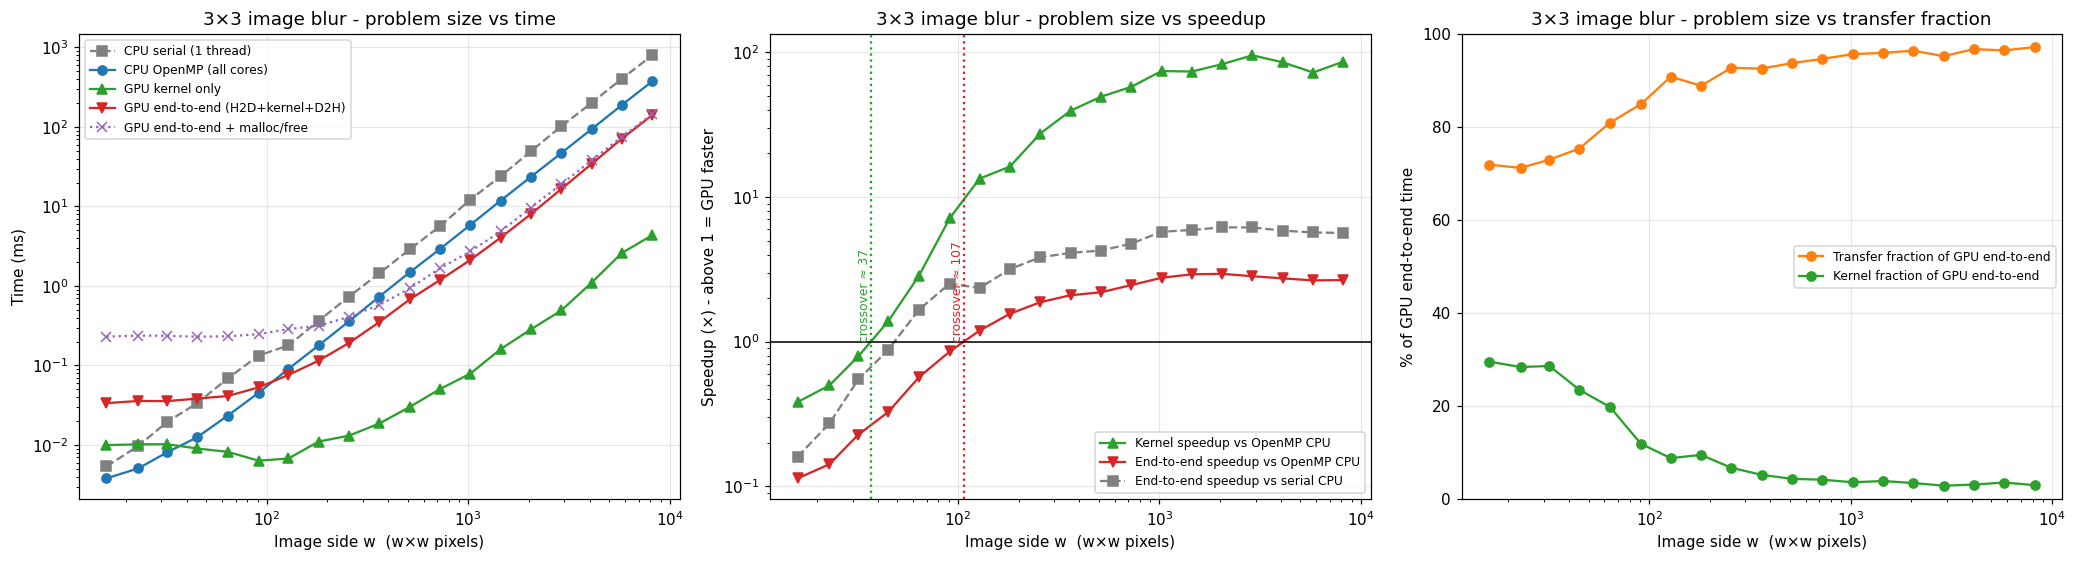

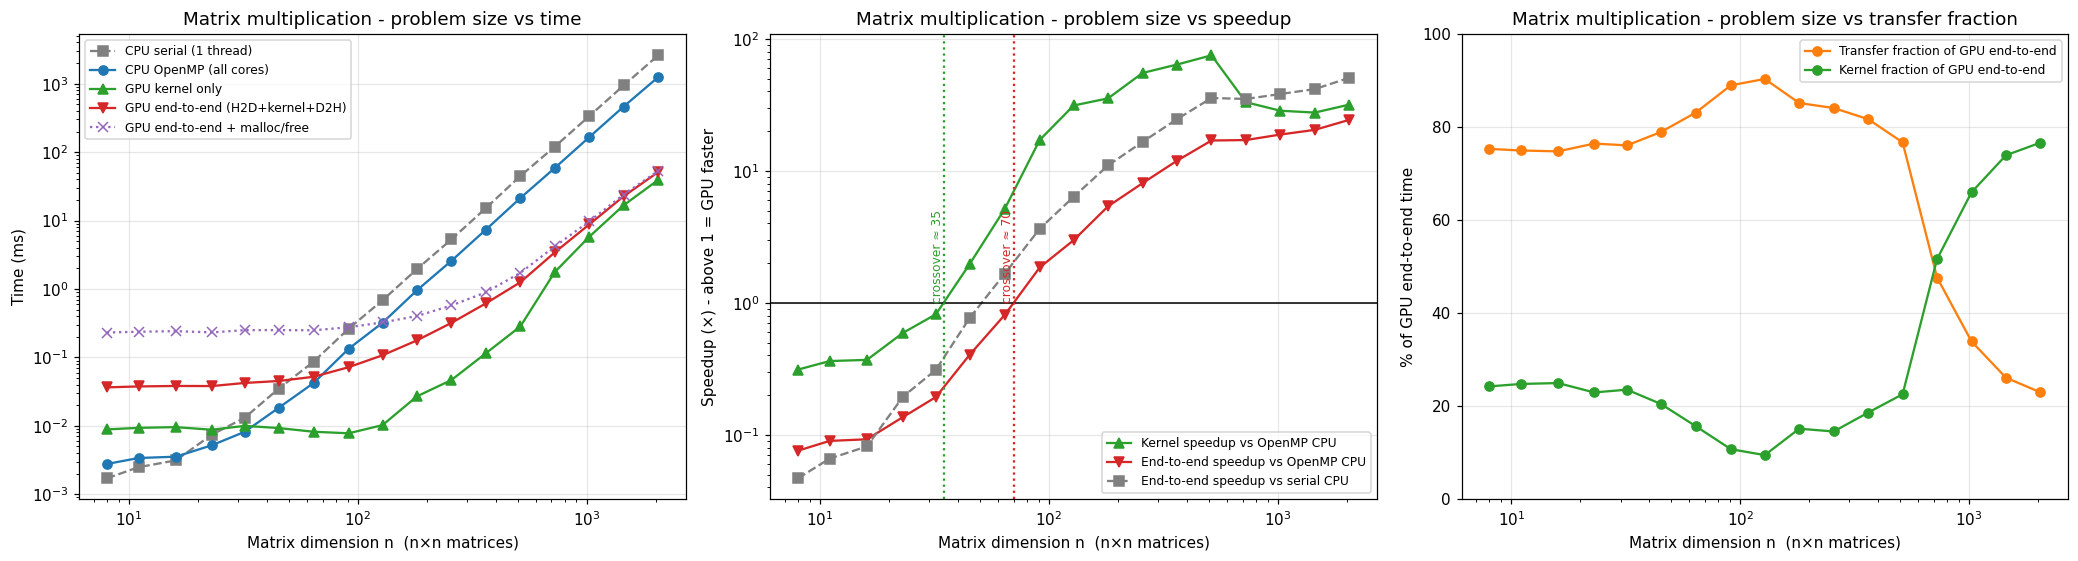

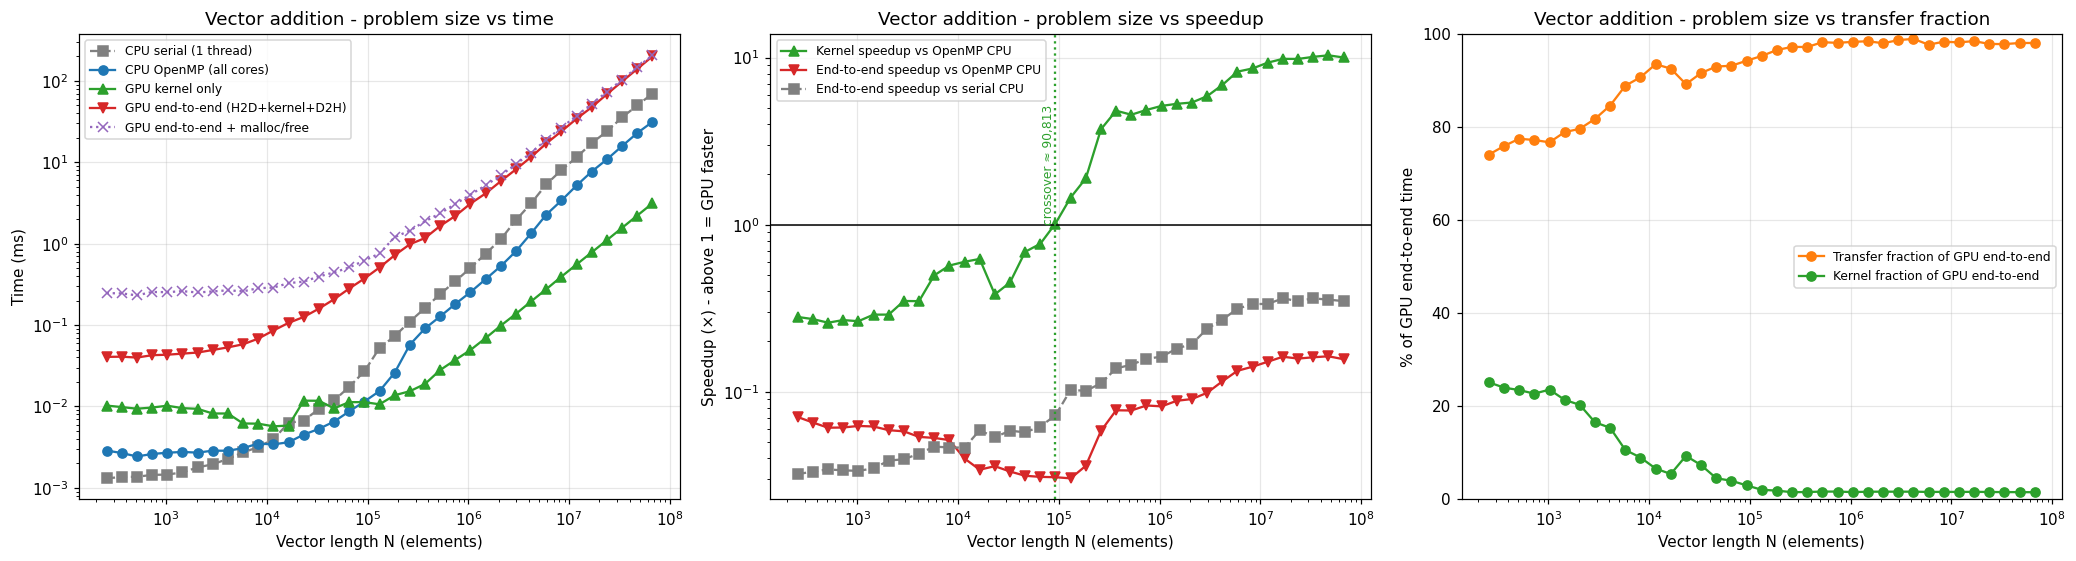

In [21]:
def plot_benchmark(b, d, savedir="results"):
    g = d[d.benchmark == b].sort_values("size")
    x = g["size"]
    fig, ax = plt.subplots(1, 3, figsize=(19, 5.2))

    # (a) time vs size
    ax[0].loglog(x, g.cpu_serial_ms, "s--", color="gray",   label="CPU serial (1 thread)")
    ax[0].loglog(x, g.cpu_omp_ms,    "o-",  color="tab:blue", label="CPU OpenMP (all cores)")
    ax[0].loglog(x, g.kernel_ms,     "^-",  color="tab:green", label="GPU kernel only")
    ax[0].loglog(x, g.e2e_ms,        "v-",  color="tab:red",   label="GPU end-to-end (H2D+kernel+D2H)")
    ax[0].loglog(x, g.e2e_alloc_ms,  "x:",  color="tab:purple", label="GPU end-to-end + malloc/free")
    ax[0].set(xlabel=XLABEL[b], ylabel="Time (ms)", title=f"{TITLE[b]} - problem size vs time"); ax[0].legend(fontsize=8)

    # (b) speedup vs size
    ax[1].semilogx(x, g.speedup_kernel_omp, "^-", color="tab:green", label="Kernel speedup vs OpenMP CPU")
    ax[1].semilogx(x, g.speedup_e2e_omp,    "v-", color="tab:red",   label="End-to-end speedup vs OpenMP CPU")
    ax[1].semilogx(x, g.speedup_e2e_ser,    "s--", color="gray",     label="End-to-end speedup vs serial CPU")
    ax[1].axhline(1, color="k", lw=1)
    for col, c in [("speedup_kernel_omp", "tab:green"), ("speedup_e2e_omp", "tab:red")]:
        _, xc, status = crossover(g["size"], g[col])
        if not np.isnan(xc):
            ax[1].axvline(xc, color=c, ls=":", lw=1.5); ax[1].annotate(f"crossover ≈ {xc:,.0f}", (xc, 1), rotation=90, va="bottom", ha="right", color=c, fontsize=8)
    ax[1].set_yscale("log")
    ax[1].set(xlabel=XLABEL[b], ylabel="Speedup (×) - above 1 = GPU faster", title=f"{TITLE[b]} - problem size vs speedup"); ax[1].legend(fontsize=8)

    # (c) transfer fraction vs size
    ax[2].semilogx(x, 100 * g.transfer_fraction, "o-", color="tab:orange", label="Transfer fraction of GPU end-to-end")
    ax[2].semilogx(x, 100 * g.kernel_fraction,   "o-", color="tab:green",  label="Kernel fraction of GPU end-to-end")
    ax[2].set(xlabel=XLABEL[b], ylabel="% of GPU end-to-end time", ylim=(0, 100), title=f"{TITLE[b]} - problem size vs transfer fraction"); ax[2].legend(fontsize=8)

    plt.tight_layout()
    fig.savefig(f"{savedir}/s02_{b}.png", bbox_inches="tight")
    plt.show()

for b in df.benchmark.unique():
    plot_benchmark(b, df)

## 9. Extra figures: cross-benchmark comparison, time breakdown, transfer bandwidth

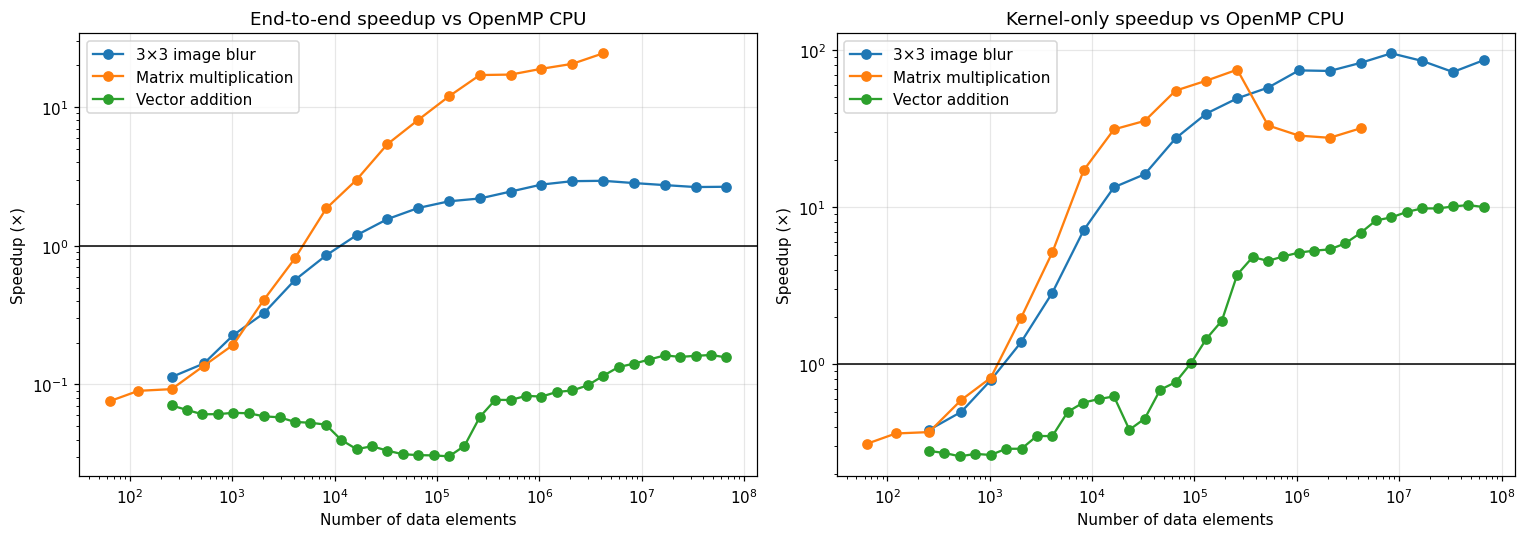

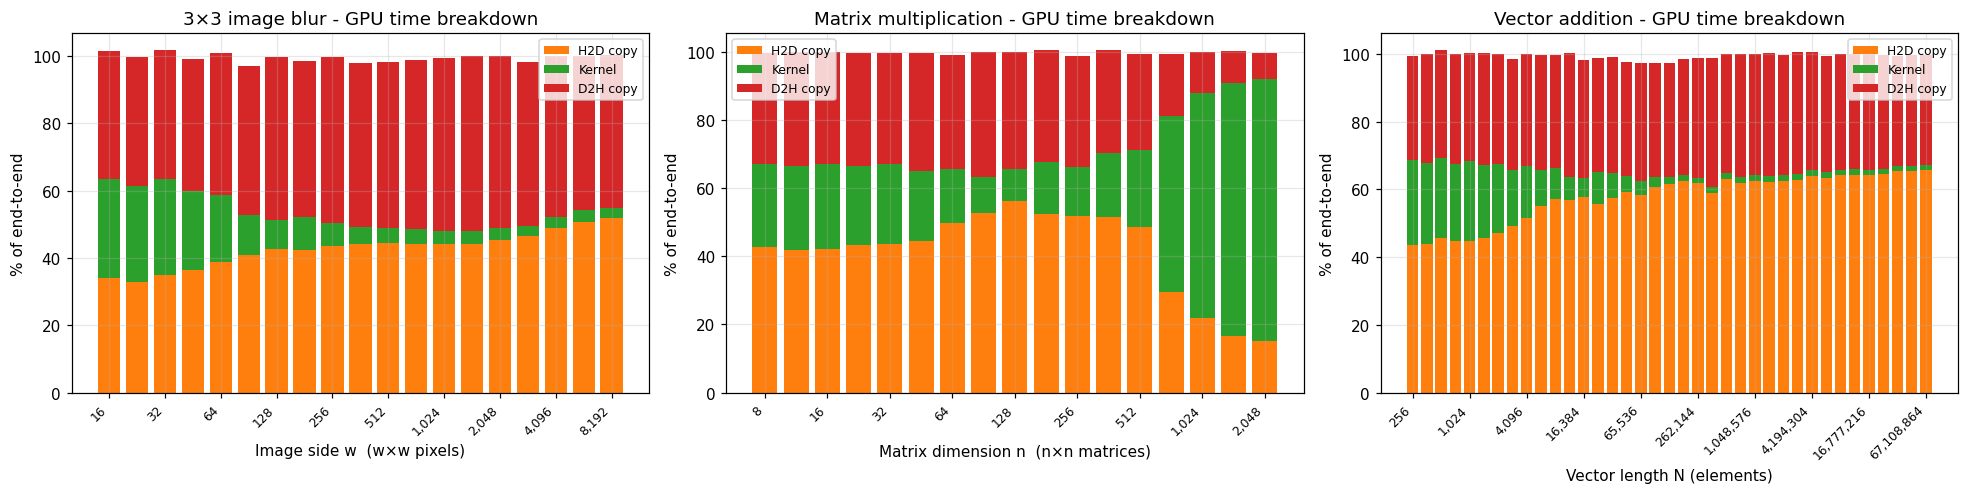

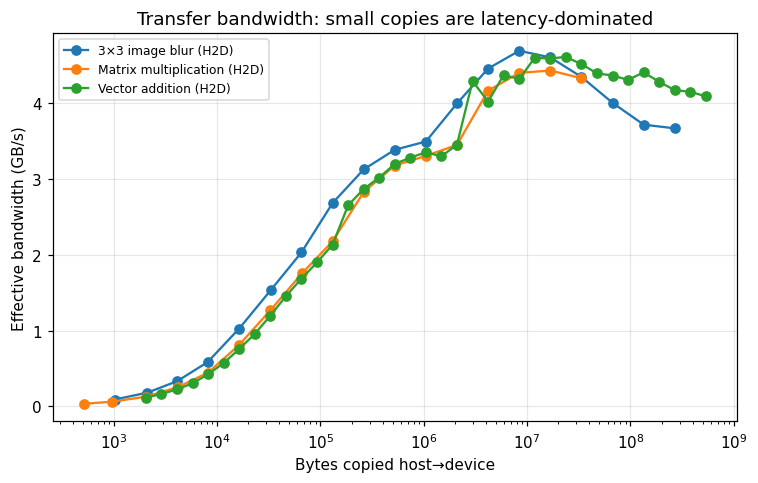

In [22]:
# --- (1) all benchmarks on one axis: end-to-end speedup vs number of elements
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for b in df.benchmark.unique():
    g = df[df.benchmark == b]
    ax[0].semilogx(g.elements, g.speedup_e2e_omp,    "o-", label=TITLE[b])
    ax[1].semilogx(g.elements, g.speedup_kernel_omp, "o-", label=TITLE[b])
for a, t in zip(ax, ["End-to-end speedup vs OpenMP CPU", "Kernel-only speedup vs OpenMP CPU"]):
    a.axhline(1, color="k", lw=1); a.set_yscale("log")
    a.set(xlabel="Number of data elements", ylabel="Speedup (×)", title=t); a.legend()
plt.tight_layout(); plt.savefig("results/s02_all_speedups.png", bbox_inches="tight"); plt.show()

# --- (2) stacked breakdown of GPU time (H2D / kernel / D2H) per size
bs = df.benchmark.unique()
fig, axes = plt.subplots(1, len(bs), figsize=(6 * len(bs), 4.6))
axes = np.atleast_1d(axes)
for a, b in zip(axes, bs):
    g = df[df.benchmark == b].sort_values("size")
    pos = np.arange(len(g))
    a.bar(pos, g.h2d_ms / g.e2e_ms * 100, label="H2D copy", color="tab:orange")
    a.bar(pos, g.kernel_ms / g.e2e_ms * 100, bottom=g.h2d_ms / g.e2e_ms * 100, label="Kernel", color="tab:green")
    a.bar(pos, g.d2h_ms / g.e2e_ms * 100, bottom=(g.h2d_ms + g.kernel_ms) / g.e2e_ms * 100, label="D2H copy", color="tab:red")
    step = max(1, len(g) // 8)
    a.set_xticks(pos[::step]); a.set_xticklabels([f"{int(s):,}" for s in g["size"].iloc[::step]], rotation=45, ha="right", fontsize=8)
    a.set(title=f"{TITLE[b]} - GPU time breakdown", xlabel=XLABEL[b], ylabel="% of end-to-end"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig("results/s02_breakdown.png", bbox_inches="tight"); plt.show()

# --- (3) effective transfer bandwidth
fig, ax = plt.subplots(figsize=(7, 4.5))
for b in bs:
    g = df[df.benchmark == b]
    ax.semilogx(g.bytes_h2d, g.h2d_GBps, "o-", label=f"{TITLE[b]} (H2D)")
ax.set(xlabel="Bytes copied host→device", ylabel="Effective bandwidth (GB/s)", title="Transfer bandwidth: small copies are latency-dominated"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("results/s02_bandwidth.png", bbox_inches="tight"); plt.show()

## 10. Optional: CUDA vs OpenMP target offload

In [23]:
if os.path.exists("results/s02_ompoffload_results.csv"):
    off = add_metrics(pd.read_csv("results/s02_ompoffload_results.csv"))
    off.to_csv("results/s02_ompoffload_results_with_metrics.csv", index=False)
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    for a, (b, ob) in zip(ax, [("vecadd", "omp_vecadd"), ("matmul", "omp_matmul")]):
        a.semilogx(df[df.benchmark == b]["size"], df[df.benchmark == b].speedup_e2e_omp,  "o-", label="CUDA end-to-end")
        a.semilogx(off[off.benchmark == ob]["size"], off[off.benchmark == ob].speedup_e2e_omp, "s-", label="OpenMP offload end-to-end")
        a.axhline(1, color="k", lw=1); a.set_yscale("log")
        a.set(title=TITLE[b], xlabel=XLABEL[b], ylabel="Speedup vs OpenMP CPU"); a.legend()
    plt.tight_layout(); plt.savefig("results/s02_cuda_vs_ompoffload.png", bbox_inches="tight"); plt.show()
    display(crossover_table(off).round(3))
else:
    print("No OpenMP-offload results (nvc++ unavailable) - skipped.")

No OpenMP-offload results (nvc++ unavailable) - skipped.


## 11. Summary table and auto-generated findings

In [24]:
summary = xt[xt.comparison.isin(["Kernel only  vs CPU-OpenMP", "End-to-end   vs CPU-OpenMP", "E2E+malloc/free vs CPU-OpenMP"])].copy()
summary["crossover_size"] = summary["crossover_size"].round(0)
display(summary[["benchmark", "comparison", "crossover_size", "first_size_GPU_wins", "max_speedup", "size_at_max", "status"]].round(2))

def fmt(v): return "n/a" if pd.isna(v) else f"{v:,.0f}"

print("\n================ FINDINGS ================\n")
for b in df.benchmark.unique():
    g = df[df.benchmark == b].sort_values("size")
    k = xt[(xt.benchmark == b) & (xt.comparison.str.startswith("Kernel only  vs CPU-OpenMP"))].iloc[0]
    e = xt[(xt.benchmark == b) & (xt.comparison.str.startswith("End-to-end   vs CPU-OpenMP"))].iloc[0]
    big = g.iloc[-1]
    print(f"[{TITLE[b]}]")
    print(f"  - Kernel-only crossover vs OpenMP CPU : {fmt(k.crossover_size)}  ({k.status})")
    print(f"  - End-to-end crossover vs OpenMP CPU  : {fmt(e.crossover_size)}  ({e.status})")
    if not (np.isnan(k.crossover_size) or np.isnan(e.crossover_size)):
        print(f"  - Transfers shift the crossover by a factor of ~{e.crossover_size / k.crossover_size:.1f}x in problem size.")
    print(f"  - At the largest size ({int(big['size']):,}): kernel speedup {big.speedup_kernel_omp:.1f}x, end-to-end speedup {big.speedup_e2e_omp:.1f}x, "
          f"transfers = {100*big.transfer_fraction:.0f}% of GPU end-to-end time.")
    print(f"  - Peak end-to-end speedup {e.max_speedup:.1f}x at size {int(e.size_at_max):,}.\n")

,benchmark,comparison,crossover_size,first_size_GPU_wins,max_speedup,size_at_max,status
0,blur,Kernel only vs CPU-OpenMP,37.0,45.0,95.54,2896,ok
1,blur,End-to-end vs CPU-OpenMP,107.0,128.0,2.94,2048,ok
4,blur,E2E+malloc/free vs CPU-OpenMP,289.0,362.0,2.59,8192,ok
5,matmul,Kernel only vs CPU-OpenMP,35.0,45.0,75.17,512,ok
6,matmul,End-to-end vs CPU-OpenMP,70.0,91.0,24.39,2048,ok
9,matmul,E2E+malloc/free vs CPU-OpenMP,129.0,181.0,23.42,2048,ok
10,vecadd,Kernel only vs CPU-OpenMP,90813.0,92682.0,10.32,47453133,ok
11,vecadd,End-to-end vs CPU-OpenMP,NaN,NaN,0.16,47453133,never (GPU not faster at any tested size)
14,vecadd,E2E+malloc/free vs CPU-OpenMP,NaN,NaN,0.16,47453133,never (GPU not faster at any tested size)



================ FINDINGS ================

[3×3 image blur]
  - Kernel-only crossover vs OpenMP CPU : 37  (ok)
  - End-to-end crossover vs OpenMP CPU  : 107  (ok)
  - Transfers shift the crossover by a factor of ~2.9x in problem size.
  - At the largest size (8,192): kernel speedup 86.4x, end-to-end speedup 2.7x, transfers = 97% of GPU end-to-end time.
  - Peak end-to-end speedup 2.9x at size 2,048.

[Matrix multiplication]
  - Kernel-only crossover vs OpenMP CPU : 35  (ok)
  - End-to-end crossover vs OpenMP CPU  : 70  (ok)
  - Transfers shift the crossover by a factor of ~2.0x in problem size.
  - At the largest size (2,048): kernel speedup 31.8x, end-to-end speedup 24.4x, transfers = 23% of GPU end-to-end time.
  - Peak end-to-end speedup 24.4x at size 2,048.

[Vector addition]
  - Kernel-only crossover vs OpenMP CPU : 90,813  (ok)
  - End-to-end crossover vs OpenMP CPU  : n/a  (never (GPU not faster at any tested size))
  - At the largest size (67,108,864): kernel speedup 10.0x, e

## 12. Discussion (auto-filled from your measured data)

The next cell writes the discussion **with your actual numbers filled in** and saves it to `results/s02_discussion.md`. Copy it into the report and adjust the wording.


In [28]:
from IPython.display import Markdown, display

NIN = {"vecadd": 2, "matmul": 2, "blur": 1}               # number of input arrays copied host->device
UNIT = {"vecadd": "N", "matmul": "n", "blur": "w"}

def xrow(b, prefix):
    return xt[(xt.benchmark == b) & (xt.comparison.str.startswith(prefix))].iloc[0]

def where(b, r):
    """human text for a crossover row"""
    if r.status == "ok":
        el = ELEMENTS[b](r.crossover_size); mb = NIN[b] * el * 4 / 1e6
        return f"{UNIT[b]} ≈ **{r.crossover_size:,.0f}** ({el:,.0f} elements, ≈ {mb:,.2f} MB of input)"
    if r.status.startswith("already"):
        return f"already faster at the smallest size tested ({UNIT[b]} = {r.first_size_GPU_wins:,.0f})"
    return f"**never** within the tested range (best speedup {r.max_speedup:.2f}× → the GPU is up to {1/r.max_speedup:.1f}× *slower*)"

K, E, A = "Kernel only  vs CPU-OpenMP", "End-to-end   vs CPU-OpenMP", "E2E+malloc/free vs CPU-OpenMP"
L = {}
for b in df.benchmark.unique():
    g = df[df.benchmark == b].sort_values("size")
    L[b] = dict(g=g, k=xrow(b, K), e=xrow(b, E), a=xrow(b, A), first=g.iloc[0], last=g.iloc[-1])

out = []
out.append("### 1. Answer to the research question — at what problem size does GPU offloading become beneficial?\n")
out.append(f"Hardware: {sh('nvidia-smi --query-gpu=name --format=csv,noheader').splitlines()[0]} + {NCORES} CPU threads (OpenMP baseline); "
           f"single precision; pageable host memory; each point is the median of {TRIALS if 'TRIALS' in globals() else 1} trial(s).\n")
for b in L:
    d = L[b]
    out.append(f"- **{TITLE[b]}**")
    out.append(f"  - Kernel-only crossover (data already on GPU): {where(b, d['k'])}.")
    out.append(f"  - End-to-end crossover (H2D + kernel + D2H): {where(b, d['e'])}.")
    out.append(f"  - End-to-end incl. `cudaMalloc/Free`: {where(b, d['a'])}.")
    if d['k'].status == 'ok' and d['e'].status == 'ok':
        out.append(f"  - Transfers push the crossover to a **{d['e'].crossover_size / d['k'].crossover_size:.1f}× larger** problem size.")
    out.append(f"  - Transfer fraction of GPU end-to-end time: {100*d['first'].transfer_fraction:.0f}% at the smallest size → {100*d['last'].transfer_fraction:.0f}% at the largest ({int(d['last']['size']):,}).")
    out.append(f"  - Largest size: kernel speedup **{d['last'].speedup_kernel_omp:.1f}×**, end-to-end speedup **{d['last'].speedup_e2e_omp:.2f}×** vs multi-core CPU "
               f"(peak end-to-end {d['e'].max_speedup:.2f}× at size {int(d['e'].size_at_max):,}).\n")

out.append("### 2. Why kernel-only and end-to-end crossovers differ\n")
out.append("Every offload pays a fixed latency (kernel launch, `cudaMemcpy` set-up, allocation) plus `bytes / PCIe bandwidth`. "
           "At small sizes the fixed cost dominates (see `s02_bandwidth.png`: tiny copies reach only a fraction of peak GB/s); at large sizes the bandwidth term dominates. "
           "The GPU wins end-to-end only when `T_cpu > T_fixed + bytes/BW + T_kernel`.\n")

out.append("### 3. Arithmetic intensity explains the ordering\n")
mm = L.get("matmul"); va = L.get("vecadd"); bl = L.get("blur")
if va: out.append(f"- Vector add does 1 FLOP per 12 bytes moved. Even with a {va['last'].speedup_kernel_omp:.1f}× faster kernel, transfers are {100*va['last'].transfer_fraction:.0f}% of GPU time, so end-to-end speedup is only {va['last'].speedup_e2e_omp:.2f}× at N = {int(va['last']['size']):,}. It is memory/PCIe-bound, so offloading a single vector add is not worthwhile unless the data stays on the GPU.")
if mm: out.append(f"- Matrix multiply does O(n³) work on O(n²) data (≈ n/6 FLOP per byte). Transfer fraction falls from {100*mm['first'].transfer_fraction:.0f}% to {100*mm['last'].transfer_fraction:.0f}% and end-to-end speedup reaches {mm['last'].speedup_e2e_omp:.1f}× at n = {int(mm['last']['size']):,}.")
if bl: out.append(f"- 3×3 blur does ~9 operations per 8 transferred bytes (constant intensity). The kernel is {bl['last'].speedup_kernel_omp:.0f}× faster than the CPU at w = {int(bl['last']['size']):,}, but transfers take {100*bl['last'].transfer_fraction:.0f}% of GPU time, so end-to-end speedup stays at {bl['last'].speedup_e2e_omp:.1f}× — it plateaus instead of growing.")
out.append("")
out.append("### 4. Rule of thumb from these data\n")
out.append("Offload only if the problem is at least the **end-to-end** crossover size *and* the work is compute-intensive or the data stays resident on the GPU across several kernels (amortising the transfers).\n")

out.append("### 5. Threats to validity\n")
out.append(f"- One hardware pair only (this GPU, its PCIe link, {NCORES} CPU hyper-threads on a shared cloud VM); a CPU with more cores moves every crossover to larger sizes.")
out.append("- Pageable host memory was used; pinned memory (`cudaMallocHost`) would raise copy bandwidth and lower the end-to-end crossover.")
out.append("- CPU matmul is a simple cache-friendly OpenMP loop (not MKL/OpenBLAS) and the GPU matmul is a shared-memory tile kernel (not cuBLAS); both are under-optimised, so absolute speedups are indicative only.")
out.append("- Single precision only; medians over repetitions and trials; GPU/CPU clock changes can still shift the smallest (microsecond-scale) points.")
if "e2e_spread" in df.columns:
    out.append(f"- Measured run-to-run spread of end-to-end time across trials: median {100*df.e2e_spread.median():.1f}% (max {100*df.e2e_spread.max():.0f}%).")
out.append("- OpenMP *target-offload* with `nvc++` is not installed on Kaggle, so the GPU side is CUDA; the CPU side uses OpenMP.\n")
out.append("### 6. Possible extensions\n")
out.append("Pinned memory, CUDA streams to overlap copy and compute, unified memory, cuBLAS / OpenBLAS comparison, double precision, a second GPU model.")

text = "\n".join(out)
open("results/s02_discussion.md", "w").write(text)
display(Markdown(text))

### 1. Answer to the research question — at what problem size does GPU offloading become beneficial?

Hardware: Tesla T4 + 4 CPU threads (OpenMP baseline); single precision; pageable host memory; each point is the median of 3 trial(s).

- **3×3 image blur**
  - Kernel-only crossover (data already on GPU): w ≈ **37** (1,365 elements, ≈ 0.01 MB of input).
  - End-to-end crossover (H2D + kernel + D2H): w ≈ **107** (11,447 elements, ≈ 0.05 MB of input).
  - End-to-end incl. `cudaMalloc/Free`: w ≈ **289** (83,262 elements, ≈ 0.33 MB of input).
  - Transfers push the crossover to a **2.9× larger** problem size.
  - Transfer fraction of GPU end-to-end time: 72% at the smallest size → 97% at the largest (8,192).
  - Largest size: kernel speedup **86.4×**, end-to-end speedup **2.66×** vs multi-core CPU (peak end-to-end 2.94× at size 2,048).

- **Matrix multiplication**
  - Kernel-only crossover (data already on GPU): n ≈ **35** (1,196 elements, ≈ 0.01 MB of input).
  - End-to-end crossover (H2D + kernel + D2H): n ≈ **70** (4,894 elements, ≈ 0.04 MB of input).
  - End-to-end incl. `cudaMalloc/Free`: n ≈ **129** (16,536 elements, ≈ 0.13 MB of input).
  - Transfers push the crossover to a **2.0× larger** problem size.
  - Transfer fraction of GPU end-to-end time: 75% at the smallest size → 23% at the largest (2,048).
  - Largest size: kernel speedup **31.8×**, end-to-end speedup **24.39×** vs multi-core CPU (peak end-to-end 24.39× at size 2,048).

- **Vector addition**
  - Kernel-only crossover (data already on GPU): N ≈ **90,813** (90,813 elements, ≈ 0.73 MB of input).
  - End-to-end crossover (H2D + kernel + D2H): **never** within the tested range (best speedup 0.16× → the GPU is up to 6.1× *slower*).
  - End-to-end incl. `cudaMalloc/Free`: **never** within the tested range (best speedup 0.16× → the GPU is up to 6.4× *slower*).
  - Transfer fraction of GPU end-to-end time: 74% at the smallest size → 98% at the largest (67,108,864).
  - Largest size: kernel speedup **10.0×**, end-to-end speedup **0.16×** vs multi-core CPU (peak end-to-end 0.16× at size 47,453,133).

### 2. Why kernel-only and end-to-end crossovers differ

Every offload pays a fixed latency (kernel launch, `cudaMemcpy` set-up, allocation) plus `bytes / PCIe bandwidth`. At small sizes the fixed cost dominates (see `s02_bandwidth.png`: tiny copies reach only a fraction of peak GB/s); at large sizes the bandwidth term dominates. The GPU wins end-to-end only when `T_cpu > T_fixed + bytes/BW + T_kernel`.

### 3. Arithmetic intensity explains the ordering

- Vector add does 1 FLOP per 12 bytes moved. Even with a 10.0× faster kernel, transfers are 98% of GPU time, so end-to-end speedup is only 0.16× at N = 67,108,864. It is memory/PCIe-bound, so offloading a single vector add is not worthwhile unless the data stays on the GPU.
- Matrix multiply does O(n³) work on O(n²) data (≈ n/6 FLOP per byte). Transfer fraction falls from 75% to 23% and end-to-end speedup reaches 24.4× at n = 2,048.
- 3×3 blur does ~9 operations per 8 transferred bytes (constant intensity). The kernel is 86× faster than the CPU at w = 8,192, but transfers take 97% of GPU time, so end-to-end speedup stays at 2.7× — it plateaus instead of growing.

### 4. Rule of thumb from these data

Offload only if the problem is at least the **end-to-end** crossover size *and* the work is compute-intensive or the data stays resident on the GPU across several kernels (amortising the transfers).

### 5. Threats to validity

- One hardware pair only (this GPU, its PCIe link, 4 CPU hyper-threads on a shared cloud VM); a CPU with more cores moves every crossover to larger sizes.
- Pageable host memory was used; pinned memory (`cudaMallocHost`) would raise copy bandwidth and lower the end-to-end crossover.
- CPU matmul is a simple cache-friendly OpenMP loop (not MKL/OpenBLAS) and the GPU matmul is a shared-memory tile kernel (not cuBLAS); both are under-optimised, so absolute speedups are indicative only.
- Single precision only; medians over repetitions and trials; GPU/CPU clock changes can still shift the smallest (microsecond-scale) points.
- Measured run-to-run spread of end-to-end time across trials: median 4.6% (max 32%).
- OpenMP *target-offload* with `nvc++` is not installed on Kaggle, so the GPU side is CUDA; the CPU side uses OpenMP.

### 6. Possible extensions

Pinned memory, CUDA streams to overlap copy and compute, unified memory, cuBLAS / OpenBLAS comparison, double precision, a second GPU model.

## 13. Package all results

In [29]:
import zipfile
from IPython.display import FileLink, display
with zipfile.ZipFile("s02_results.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(os.listdir("results")):
        z.write(os.path.join("results", f))
    for f in ["s02_bench.cu", "s02_omp_offload.cpp"]:
        if os.path.exists(f): z.write(f)
print("Created s02_results.zip with:", sorted(os.listdir("results")))
print("Kaggle: files are in /kaggle/working -> open the 'Output' tab on the right (after 'Save Version' / Run All) to download.")
display(FileLink("s02_results.zip"))


Created s02_results.zip with: ['s02_all_speedups.png', 's02_bandwidth.png', 's02_blur.png', 's02_breakdown.png', 's02_crossover_table.csv', 's02_cuda_results.csv', 's02_cuda_results_all_trials.csv', 's02_cuda_results_with_metrics.csv', 's02_discussion.md', 's02_matmul.png', 's02_vecadd.png', 'system_info.txt']
Kaggle: files are in /kaggle/working -> open the 'Output' tab on the right (after 'Save Version' / Run All) to download.


/kaggle/working/s02_results.zip

In [31]:
!find /usr/local /usr/lib /opt -type f \( \
    -name 'clang++*' -o \
    -name 'nvptx*' -o \
    -name 'libomptarget-*.bc' -o \
    -name 'libomptarget.rtl.cuda.so' \
\) 2>/dev/null | head -80

!g++ -print-file-name=libgomp.so
!apt-cache policy gcc-14-offload-nvptx
!nvidia-smi

/usr/local/lib/python3.13/dist-packages/tensorflow/include/tensorflow/compiler/xla/stream_executor/cuda/nvptxcompiler_compilation_provider.h
/usr/local/lib/python3.13/dist-packages/tensorflow/include/tensorflow/compiler/xla/service/gpu/nvptx_alias_info.h
/usr/local/lib/python3.13/dist-packages/tensorflow/include/tensorflow/compiler/xla/service/gpu/nvptx_compiler.h
/usr/local/lib/python3.13/dist-packages/tensorflow/include/tensorflow/compiler/xla/service/gpu/llvm_gpu_backend/nvptx_backend.h
/usr/local/lib/python3.13/dist-packages/tensorflow/include/tensorflow/compiler/xla/service/gpu/llvm_gpu_backend/nvptx_utils.h
/usr/local/lib/python3.13/dist-packages/tensorflow/include/tensorflow/compiler/xla/service/gpu/llvm_gpu_backend/nvptx_libdevice_path.h
/usr/local/lib/python3.13/dist-packages/tensorflow/include/xla/stream_executor/cuda/nvptxcompiler_compilation_provider.h
/usr/local/lib/python3.13/dist-packages/tensorflow/include/xla/service/gpu/nvptx_alias_info.h
/usr/local/lib/python3.13/dis

In [32]:
!apt-get update -qq
!apt-get install -y gcc-14 g++-14 gcc-14-offload-nvptx

W: https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for details.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  cpp-14 cpp-14-x86-64-linux-gnu g++-14-x86-64-linux-gnu
  gcc-14-x86-64-linux-gnu libgcc-14-dev libgomp-plugin-nvptx1 libstdc++-14-dev
  nvptx-tools
Suggested packages:
  gcc-14-locales cpp-14-doc g++-14-multilib gcc-14-doc gcc-14-multilib
  libcuda1 | libnvidia-tesla-cuda1 | libcuda1-any libstdc++-14-doc
  nvidia-cuda-toolkit
The following NEW packages will be installed:
  cpp-14 cpp-14-x86-64-linux-gnu g++-14 g++-14-x86-64-linux-gnu gcc-14
  

In [33]:
%%writefile omp_gpu_test.cpp
#include <cstdio>
#include <omp.h>

int main() {
    printf("Number of OpenMP devices: %d\n", omp_get_num_devices());

    int ran_on_gpu = 0;

    #pragma omp target map(from: ran_on_gpu)
    {
        ran_on_gpu = !omp_is_initial_device();
    }

    printf("Executed on GPU: %s\n", ran_on_gpu ? "YES" : "NO");
    return ran_on_gpu ? 0 : 1;
}

Writing omp_gpu_test.cpp


In [35]:
!g++-14 -O2 -fopenmp -foffload=nvptx-none \
  -fcf-protection=none \
  omp_gpu_test.cpp -o omp_gpu_test

/usr/bin/ld: /tmp/cc4sHgqE.crtoffloadtable.o: warning: relocation against `__offload_vars_end' in read-only section `.rodata'
/usr/bin/ld: warning: creating DT_TEXTREL in a PIE


In [36]:
!OMP_TARGET_OFFLOAD=MANDATORY ./omp_gpu_test

Number of OpenMP devices: 1
Executed on GPU: YES


In [40]:
!g++-14 -O3 -fopenmp \
  -foffload=nvptx-none \
  -fcf-protection=none \
  -fno-stack-protector \
  -foffload-options=nvptx-none=-fno-stack-protector \
  s02_omp_offload.cpp -o s02_omp_offload

/usr/bin/ld: /tmp/cc4d56Yz.crtoffloadtable.o: warning: relocation against `__offload_funcs_end' in read-only section `.rodata'
/usr/bin/ld: warning: creating DT_TEXTREL in a PIE


In [41]:
!OMP_TARGET_OFFLOAD=MANDATORY ./s02_omp_offload vecadd quick

benchmark,size,cpu_serial_ms,cpu_omp_ms,alloc_ms,h2d_ms,kernel_ms,d2h_ms,e2e_ms,e2e_alloc_ms,bytes_h2d,bytes_d2h,max_rel_err
omp_vecadd,256,0.001392,0.002517,0,0.128460,0.853856,0.114922,1.105495,1.105495,2048,1024,0.000e+00
[omp_vecadd] size=256 kernel=0.854 ms e2e=1.105 ms
omp_vecadd,512,0.001505,0.002555,0,0.129096,0.857597,0.118286,1.103436,1.103436,4096,2048,0.000e+00
[omp_vecadd] size=512 kernel=0.858 ms e2e=1.103 ms
omp_vecadd,1024,0.001557,0.002631,0,0.131396,0.479551,0.113519,0.731805,0.731805,8192,4096,0.000e+00
[omp_vecadd] size=1024 kernel=0.480 ms e2e=0.732 ms
omp_vecadd,2048,0.001837,0.002664,0,0.134855,0.476245,0.115479,0.738868,0.738868,16384,8192,0.000e+00
[omp_vecadd] size=2048 kernel=0.476 ms e2e=0.739 ms
omp_vecadd,4096,0.002437,0.002854,0,0.138623,0.475918,0.122280,0.745705,0.745705,32768,16384,0.000e+00
[omp_vecadd] size=4096 kernel=0.476 ms e2e=0.746 ms
omp_vecadd,8192,0.003301,0.002965,0,0.142560,0.458579,0.121793,0.735929,0.735929,65536,32768,0.000e+00
[omp_vec

In [42]:
!OMP_TARGET_OFFLOAD=MANDATORY ./s02_omp_offload matmul quick

benchmark,size,cpu_serial_ms,cpu_omp_ms,alloc_ms,h2d_ms,kernel_ms,d2h_ms,e2e_ms,e2e_alloc_ms,bytes_h2d,bytes_d2h,max_rel_err
omp_matmul,8,0.001709,0.002913,0,0.116956,0.375769,0.099517,0.593212,0.593212,512,256,1.283e-07
[omp_matmul] size=8 kernel=0.376 ms e2e=0.593 ms
omp_matmul,16,0.002931,0.003276,0,0.128539,0.598929,0.113945,0.847211,0.847211,2048,1024,1.122e-07
[omp_matmul] size=16 kernel=0.599 ms e2e=0.847 ms
omp_matmul,32,0.010958,0.008510,0,0.130334,0.451992,0.116830,0.711947,0.711947,8192,4096,8.108e-08
[omp_matmul] size=32 kernel=0.452 ms e2e=0.712 ms
omp_matmul,64,0.073641,0.033261,0,0.127069,0.457111,0.103444,0.687252,0.687252,32768,16384,1.665e-07
[omp_matmul] size=64 kernel=0.457 ms e2e=0.687 ms
omp_matmul,128,0.596292,0.236737,0,0.176805,0.644808,0.148499,0.970042,0.970042,131072,65536,2.701e-07
[omp_matmul] size=128 kernel=0.645 ms e2e=0.970 ms
omp_matmul,256,5.046719,1.800250,0,0.269521,2.133287,0.208421,2.622142,2.622142,524288,262144,1.951e-07
[omp_matmul] size=256 k

In [44]:
import os
import io
import time
import subprocess
import pandas as pd
import numpy as np

os.makedirs("results", exist_ok=True)

TRIALS = 3
all_trials = []

def run_offload(benchmark, quick=False):
    cmd = ["./s02_omp_offload", benchmark]
    if quick:
        cmd.append("quick")

    env = os.environ.copy()
    env["OMP_TARGET_OFFLOAD"] = "MANDATORY"

    result = subprocess.run(
        cmd,
        capture_output=True,
        text=True,
        env=env,
        check=True
    )

    # The benchmark emits CSV on stdout and diagnostic timing lines on stderr.
    data = pd.read_csv(io.StringIO(result.stdout))
    data.columns = data.columns.str.strip()
    data["benchmark"] = data["benchmark"].str.strip()
    return data

start = time.time()

for trial in range(1, TRIALS + 1):
    print(f"Trial {trial}/{TRIALS}")

    # Quick vector sweep: up to 4,194,304 elements.
    v = run_offload("vecadd", quick=True)
    v["trial"] = trial
    all_trials.append(v)

    # Full matrix sweep: logarithmic sizes up to 2048.
    m = run_offload("matmul", quick=False)
    m["trial"] = trial
    all_trials.append(m)

trials_df = pd.concat(all_trials, ignore_index=True)
trials_df.to_csv("results/s02_offload_all_trials.csv", index=False)

# Median timing across independent program runs; preserve correctness and byte counts.
time_cols = [
    "cpu_serial_ms", "cpu_omp_ms", "alloc_ms",
    "h2d_ms", "kernel_ms", "d2h_ms", "e2e_ms", "e2e_alloc_ms"
]

group_cols = ["benchmark", "size"]
g = trials_df.groupby(group_cols, sort=True)

summary = g[time_cols].median().reset_index()
summary["bytes_h2d"] = g["bytes_h2d"].first().values
summary["bytes_d2h"] = g["bytes_d2h"].first().values
summary["max_rel_err"] = g["max_rel_err"].max().values
summary["trial_count"] = g["trial"].nunique().values

# Run-to-run variability: (maximum - minimum) / median.
for col in ["cpu_serial_ms", "cpu_omp_ms", "kernel_ms", "e2e_ms"]:
    spread = g[col].agg(lambda x: (x.max() - x.min()) / x.median()
                        if x.median() else np.nan)
    summary[f"{col.replace('_ms', '')}_spread"] = spread.values

summary.to_csv("results/s02_offload_results.csv", index=False)

print(f"\nCompleted in {(time.time()-start)/60:.1f} minutes")
print("Raw runs: results/s02_offload_all_trials.csv")
print("Median results: results/s02_offload_results.csv")
print(f"Rows: {len(summary)}")
display(summary.tail(10))

Trial 1/3
Trial 2/3
Trial 3/3

Completed in 2.0 minutes
Raw runs: results/s02_offload_all_trials.csv
Median results: results/s02_offload_results.csv
Rows: 32


,benchmark,size,cpu_serial_ms,cpu_omp_ms,alloc_ms,h2d_ms,kernel_ms,d2h_ms,e2e_ms,e2e_alloc_ms,bytes_h2d,bytes_d2h,max_rel_err,trial_count,cpu_serial_spread,cpu_omp_spread,kernel_spread,e2e_spread
22,omp_vecadd,8192,0.003429,0.003343,0.0,0.137910,0.438252,0.111758,0.687678,0.687678,65536,32768,0.0,3,0.052493,0.184266,0.004112,0.049186
23,omp_vecadd,16384,0.005210,0.003585,0.0,0.152240,0.444989,0.125391,0.722339,0.722339,131072,65536,0.0,3,0.022457,0.085356,0.010077,0.076320
24,omp_vecadd,32768,0.009173,0.005250,0.0,0.193685,0.450372,0.156765,0.814646,0.814646,262144,131072,0.0,3,0.057887,0.092571,0.005527,0.026149
25,omp_vecadd,65536,0.017815,0.008559,0.0,0.263603,0.465167,0.207263,0.947276,0.947276,524288,262144,0.0,3,1.490373,2.198738,0.007989,0.034674
26,omp_vecadd,131072,0.054810,0.020128,0.0,0.389115,0.498565,0.288491,1.191896,1.191896,1048576,524288,0.0,3,0.145667,0.022158,0.006783,0.036239
27,omp_vecadd,262144,0.124590,0.067109,0.0,0.819865,0.490131,0.637719,1.946950,1.946950,2097152,1048576,0.0,3,0.309126,0.247865,0.009679,0.075166
28,omp_vecadd,524288,0.257069,0.126754,0.0,1.273624,0.735232,1.008235,3.039513,3.039513,4194304,2097152,0.0,3,0.019633,0.047927,0.016339,0.035822
29,omp_vecadd,1048576,0.508813,0.258637,0.0,2.173486,0.835992,1.609122,4.620179,4.620179,8388608,4194304,0.0,3,0.031180,0.018973,0.013297,0.044814
30,omp_vecadd,2097152,1.159937,0.531139,0.0,3.985744,1.050069,2.825633,7.861253,7.861253,16777216,8388608,0.0,3,0.147047,0.005641,0.004685,0.018121
31,omp_vecadd,4194304,3.266781,1.325775,0.0,7.759691,1.460885,5.252450,14.449037,14.449037,33554432,16777216,0.0,3,0.036920,0.024754,0.016346,0.021661


In [45]:
import numpy as np
import pandas as pd
import os

df = pd.read_csv("results/s02_offload_results.csv")
df = df.sort_values(["benchmark", "size"]).reset_index(drop=True)

# Total data-transfer time and transfer fraction.
df["transfer_ms"] = df["h2d_ms"] + df["d2h_ms"]
df["transfer_fraction"] = (
    df["transfer_ms"] / df["e2e_ms"].replace(0, np.nan)
)
df["kernel_fraction"] = (
    df["kernel_ms"] / df["e2e_ms"].replace(0, np.nan)
)

# Speedup: >1 means GPU is faster; <1 means CPU is faster.
df["speedup_kernel_vs_serial"] = df["cpu_serial_ms"] / df["kernel_ms"]
df["speedup_kernel_vs_omp"] = df["cpu_omp_ms"] / df["kernel_ms"]
df["speedup_e2e_vs_serial"] = df["cpu_serial_ms"] / df["e2e_ms"]
df["speedup_e2e_vs_omp"] = df["cpu_omp_ms"] / df["e2e_ms"]

# Additional measurements useful for discussion.
df["h2d_GBps"] = (
    df["bytes_h2d"] / (df["h2d_ms"] / 1000) / 1e9
)
df["d2h_GBps"] = (
    df["bytes_d2h"] / (df["d2h_ms"] / 1000) / 1e9
)
df["gpu_advantage_vs_omp"] = df["speedup_e2e_vs_omp"] > 1
df["gpu_advantage_vs_serial"] = df["speedup_e2e_vs_serial"] > 1

df.to_csv("results/s02_offload_analysis.csv", index=False)

# Locate the first observed size at which GPU end-to-end beats each CPU baseline.
def crossover_table(data):
    rows = []
    for benchmark, part in data.groupby("benchmark"):
        part = part.sort_values("size")
        for baseline, col in [
            ("CPU serial", "speedup_e2e_vs_serial"),
            ("CPU OpenMP", "speedup_e2e_vs_omp")
        ]:
            crossed = part[part[col] > 1]
            if len(crossed):
                first = crossed.iloc[0]
                rows.append({
                    "benchmark": benchmark,
                    "baseline": baseline,
                    "first_observed_crossover_size": int(first["size"]),
                    "GPU_e2e_ms": first["e2e_ms"],
                    "CPU_baseline_ms": (
                        first["cpu_serial_ms"]
                        if baseline == "CPU serial"
                        else first["cpu_omp_ms"]
                    ),
                    "end_to_end_speedup": first[col],
                    "status": "Observed in tested range"
                })
            else:
                rows.append({
                    "benchmark": benchmark,
                    "baseline": baseline,
                    "first_observed_crossover_size": None,
                    "GPU_e2e_ms": None,
                    "CPU_baseline_ms": None,
                    "end_to_end_speedup": None,
                    "status": "Not observed in tested range"
                })
    return pd.DataFrame(rows)

crossovers = crossover_table(df)
crossovers.to_csv("results/s02_crossover_table.csv", index=False)

# One-row-per-workload summary at the largest tested size.
largest = (
    df.sort_values("size")
      .groupby("benchmark", as_index=False)
      .tail(1)
      .copy()
)
largest = largest[[
    "benchmark", "size", "cpu_serial_ms", "cpu_omp_ms",
    "kernel_ms", "e2e_ms", "transfer_ms", "transfer_fraction",
    "speedup_e2e_vs_serial", "speedup_e2e_vs_omp", "max_rel_err"
]]
largest.to_csv("results/s02_largest_size_summary.csv", index=False)

print("Correctness check: maximum relative error by workload")
display(df.groupby("benchmark")["max_rel_err"].max().to_frame())

print("\nCrossover table")
display(crossovers.round(4))

print("\nLargest tested size")
display(largest.round(4))

print("\nMedian run-to-run spread (lower is more stable)")
spread_cols = [c for c in df.columns if c.endswith("_spread")]
if spread_cols:
    display(df.groupby("benchmark")[spread_cols].median().round(3))

Correctness check: maximum relative error by workload


,max_rel_err
benchmark,
omp_matmul,3.799000e-07
omp_vecadd,0.000000e+00



Crossover table


,benchmark,baseline,first_observed_crossover_size,GPU_e2e_ms,CPU_baseline_ms,end_to_end_speedup,status
0,omp_matmul,CPU serial,181.0,1.4136,1.8808,1.3305,Observed in tested range
1,omp_matmul,CPU OpenMP,NaN,NaN,NaN,NaN,Not observed in tested range
2,omp_vecadd,CPU serial,NaN,NaN,NaN,NaN,Not observed in tested range
3,omp_vecadd,CPU OpenMP,NaN,NaN,NaN,NaN,Not observed in tested range



Largest tested size


,benchmark,size,cpu_serial_ms,cpu_omp_ms,kernel_ms,e2e_ms,transfer_ms,transfer_fraction,speedup_e2e_vs_serial,speedup_e2e_vs_omp,max_rel_err
16,omp_matmul,2048,1980.0064,919.4627,3117.0221,3130.9658,13.8506,0.0044,0.6324,0.2937,0.0
31,omp_vecadd,4194304,3.2668,1.3258,1.4609,14.4490,13.0121,0.9006,0.2261,0.0918,0.0



Median run-to-run spread (lower is more stable)


,cpu_serial_spread,cpu_omp_spread,kernel_spread,e2e_spread
benchmark,,,,
omp_matmul,0.069,0.038,0.010,0.051
omp_vecadd,0.058,0.093,0.008,0.045


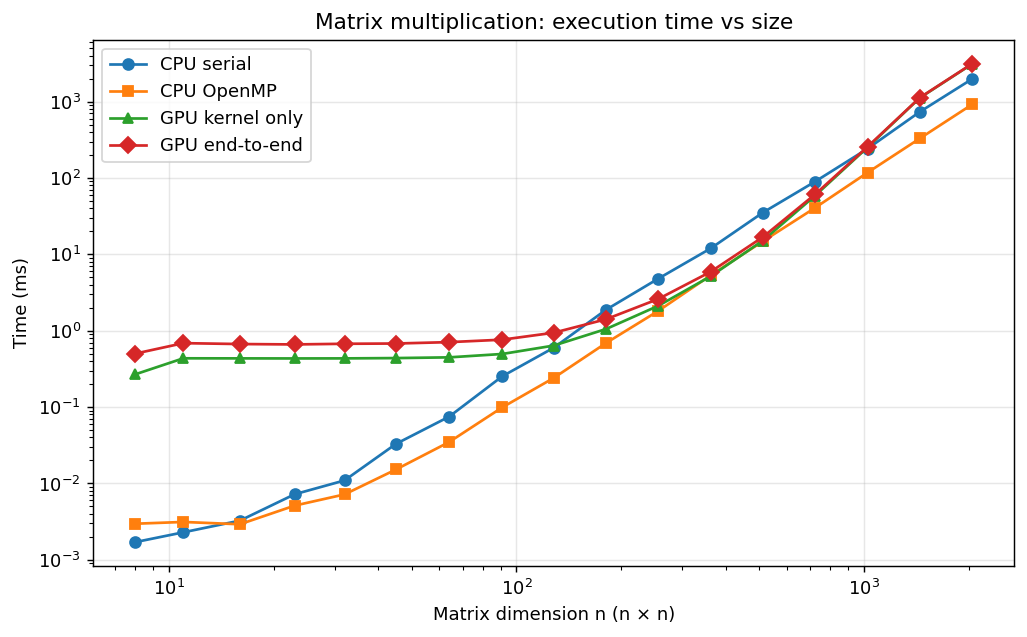

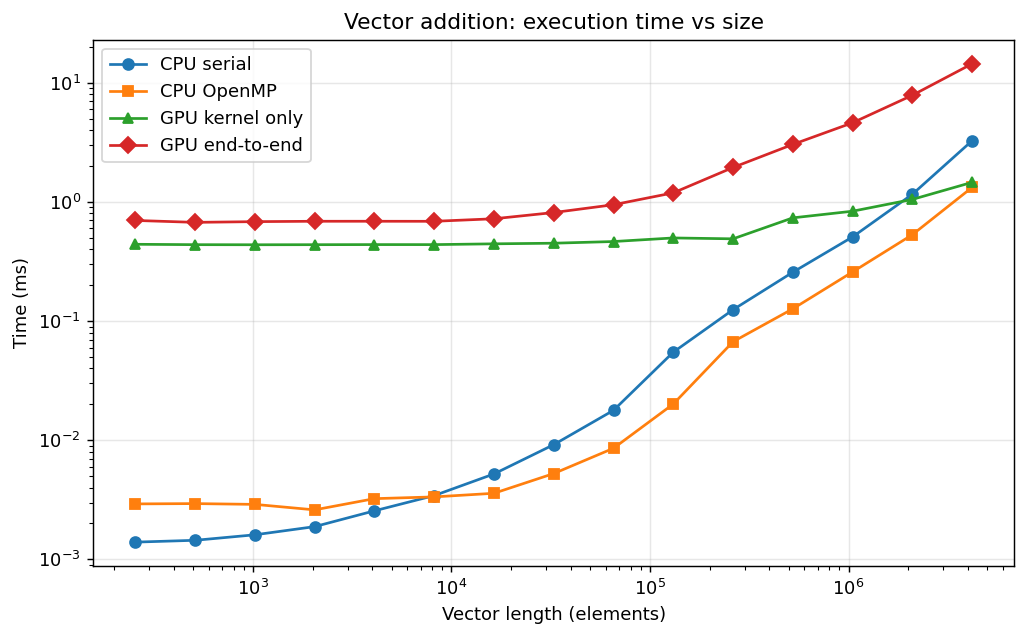

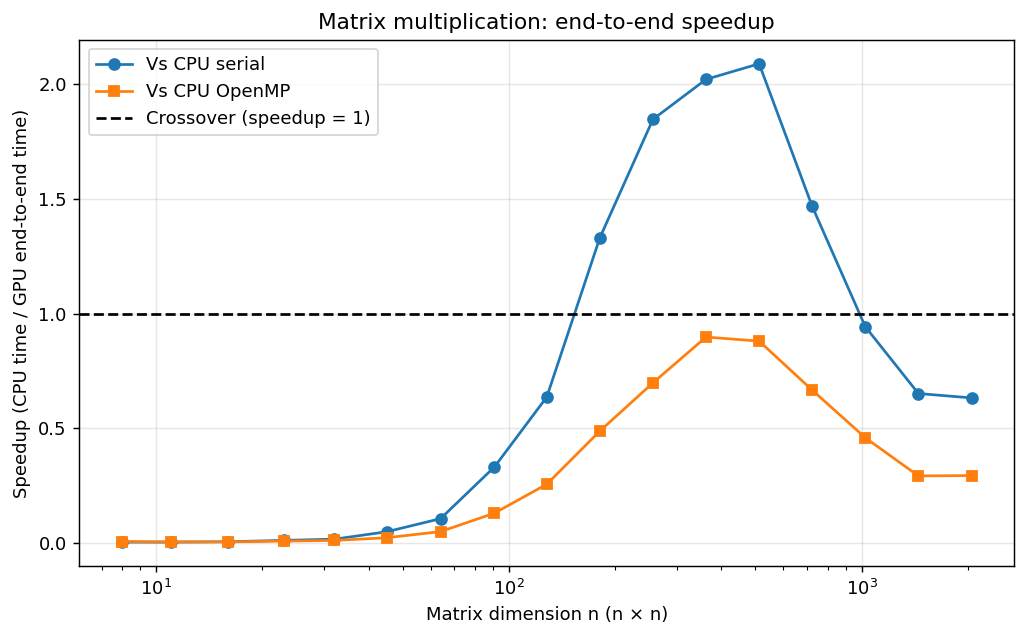

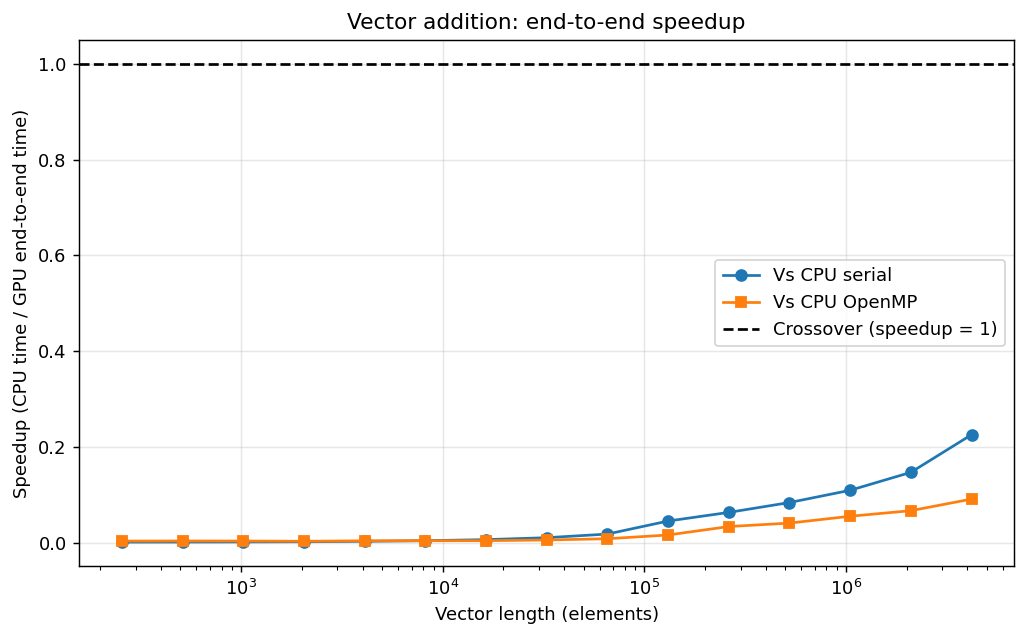

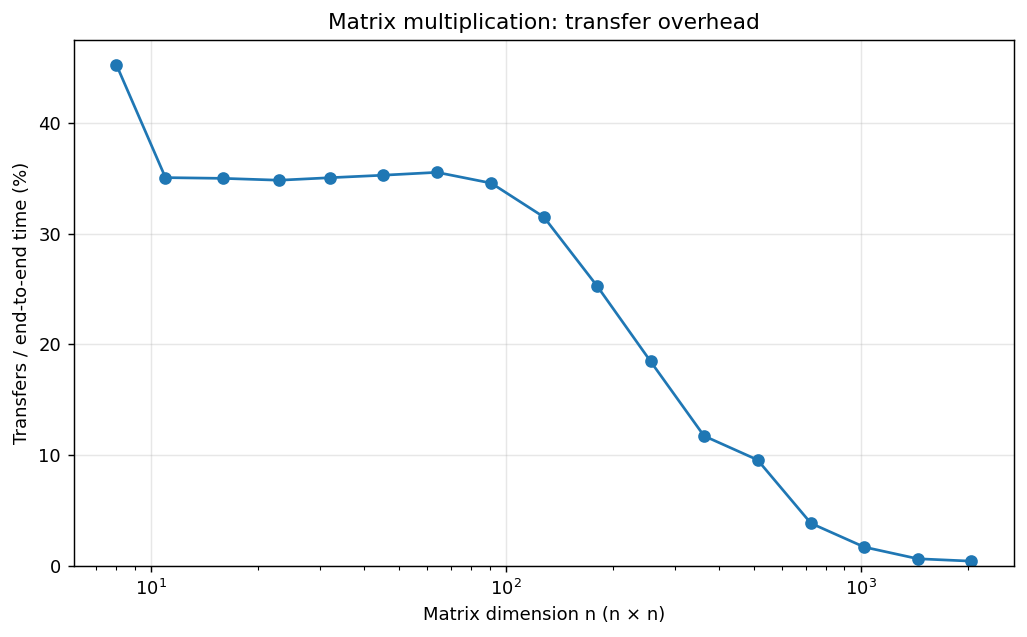

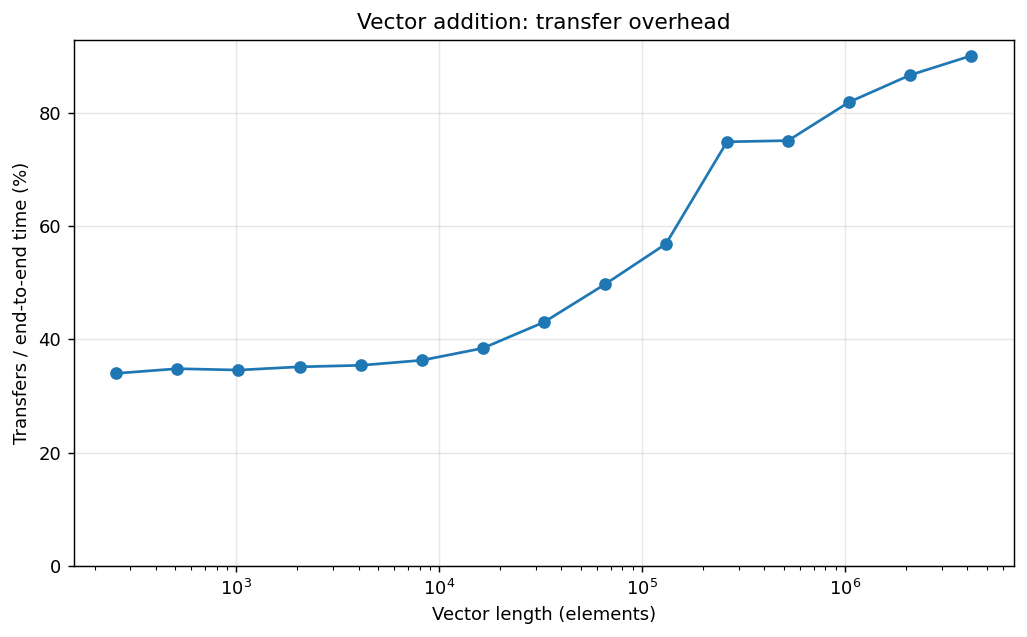

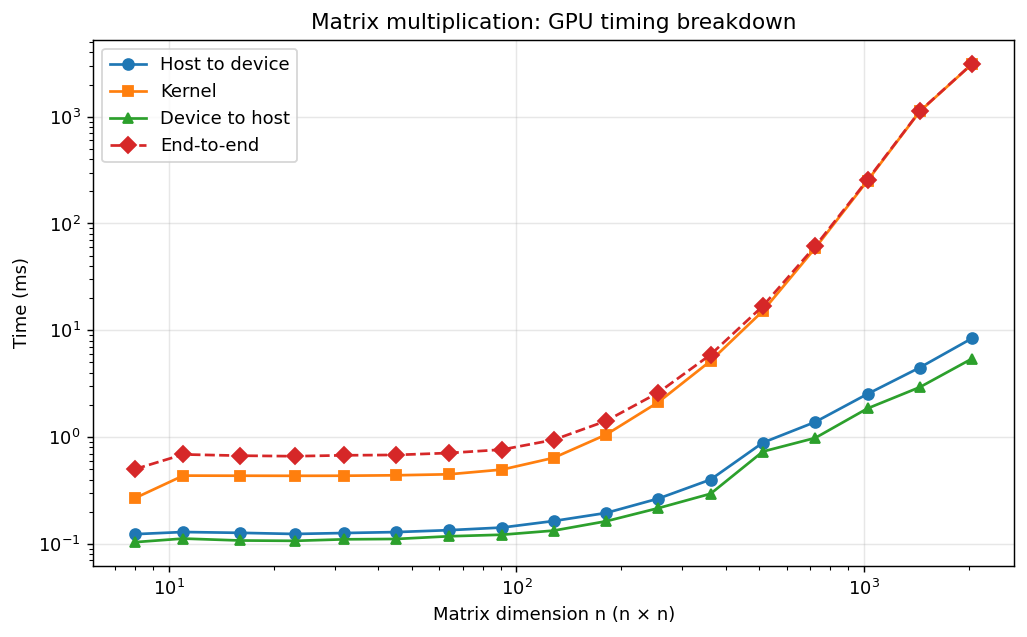

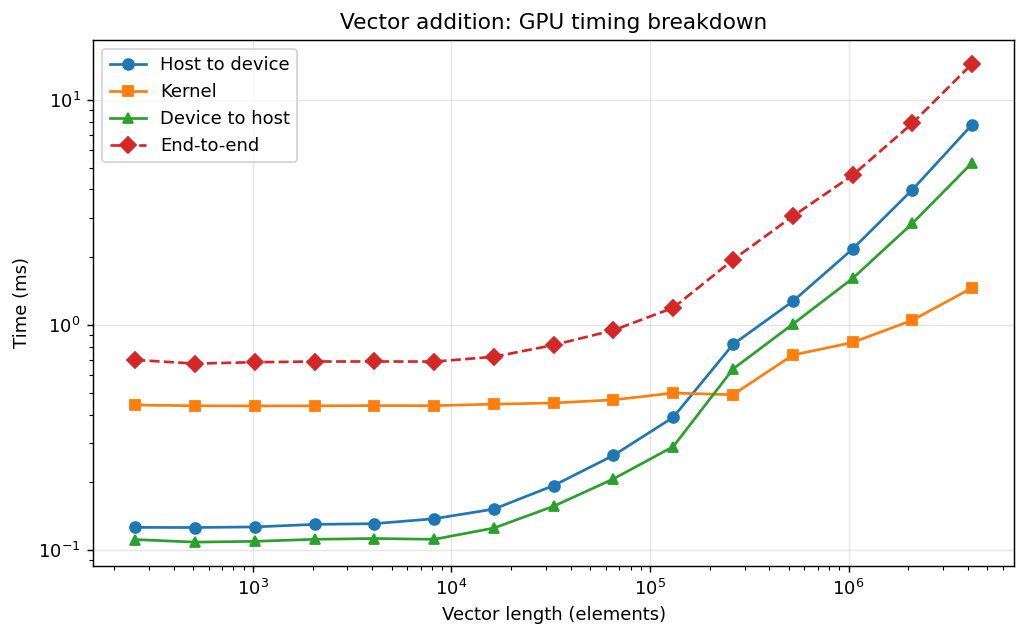

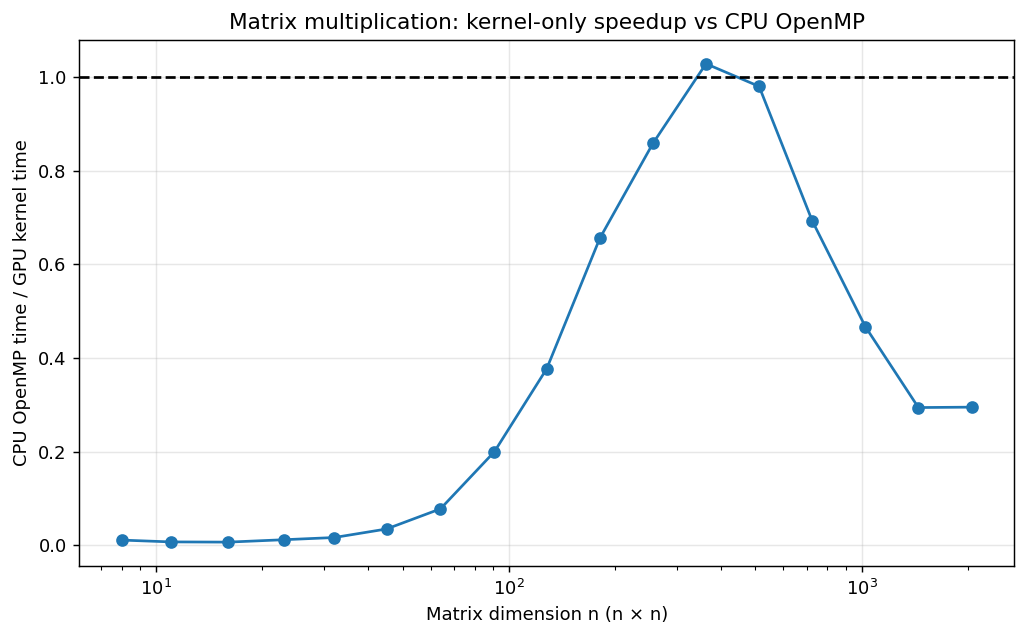

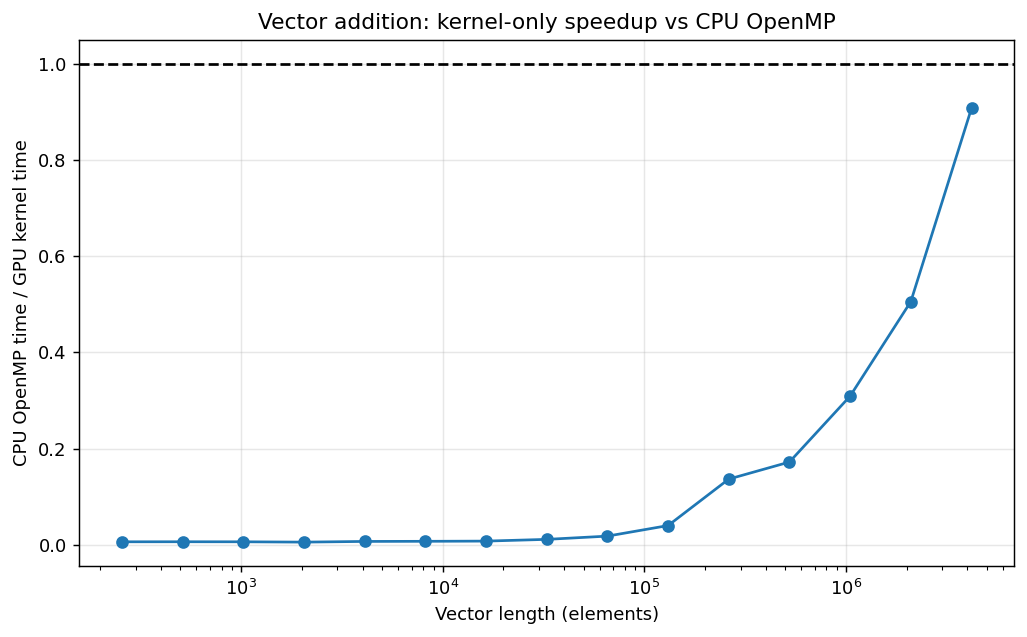

All figures saved under results/figures/


In [46]:
import matplotlib.pyplot as plt
import os

os.makedirs("results/figures", exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 200,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10
})

# Human-readable names and size labels.
labels = {
    "omp_vecadd": ("Vector addition", "Vector length (elements)"),
    "omp_matmul": ("Matrix multiplication", "Matrix dimension n (n × n)")
}

# 1. Execution time vs problem size: CPU serial, CPU OpenMP, GPU kernel, GPU end-to-end.
for benchmark, part in df.groupby("benchmark"):
    part = part.sort_values("size")
    title, xlabel = labels.get(benchmark, (benchmark, "Problem size"))

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.loglog(part["size"], part["cpu_serial_ms"], "o-", label="CPU serial")
    ax.loglog(part["size"], part["cpu_omp_ms"], "s-", label="CPU OpenMP")
    ax.loglog(part["size"], part["kernel_ms"], "^-", label="GPU kernel only")
    ax.loglog(part["size"], part["e2e_ms"], "D-", label="GPU end-to-end")
    ax.set(title=f"{title}: execution time vs size",
           xlabel=xlabel, ylabel="Time (ms)")
    ax.legend()
    fig.tight_layout()
    stem = f"results/figures/{benchmark}_time_vs_size"
    fig.savefig(stem + ".png", bbox_inches="tight")
    fig.savefig(stem + ".pdf", bbox_inches="tight")
    plt.show()

# 2. End-to-end speedup vs size. A speedup of 1 is the crossover line.
for benchmark, part in df.groupby("benchmark"):
    part = part.sort_values("size")
    title, xlabel = labels.get(benchmark, (benchmark, "Problem size"))

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.semilogx(part["size"], part["speedup_e2e_vs_serial"],
                "o-", label="Vs CPU serial")
    ax.semilogx(part["size"], part["speedup_e2e_vs_omp"],
                "s-", label="Vs CPU OpenMP")
    ax.axhline(1, color="black", linestyle="--", label="Crossover (speedup = 1)")
    ax.set(title=f"{title}: end-to-end speedup",
           xlabel=xlabel, ylabel="Speedup (CPU time / GPU end-to-end time)")
    ax.legend()
    fig.tight_layout()
    stem = f"results/figures/{benchmark}_speedup_vs_size"
    fig.savefig(stem + ".png", bbox_inches="tight")
    fig.savefig(stem + ".pdf", bbox_inches="tight")
    plt.show()

# 3. Transfer fraction vs size.
for benchmark, part in df.groupby("benchmark"):
    part = part.sort_values("size")
    title, xlabel = labels.get(benchmark, (benchmark, "Problem size"))

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.semilogx(part["size"], 100 * part["transfer_fraction"], "o-")
    ax.set(title=f"{title}: transfer overhead",
           xlabel=xlabel, ylabel="Transfers / end-to-end time (%)")
    ax.set_ylim(bottom=0)
    fig.tight_layout()
    stem = f"results/figures/{benchmark}_transfer_fraction"
    fig.savefig(stem + ".png", bbox_inches="tight")
    fig.savefig(stem + ".pdf", bbox_inches="tight")
    plt.show()

# 4. Timing decomposition: H->D, kernel, D->H.
for benchmark, part in df.groupby("benchmark"):
    part = part.sort_values("size")
    title, xlabel = labels.get(benchmark, (benchmark, "Problem size"))

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.loglog(part["size"], part["h2d_ms"], "o-", label="Host to device")
    ax.loglog(part["size"], part["kernel_ms"], "s-", label="Kernel")
    ax.loglog(part["size"], part["d2h_ms"], "^-", label="Device to host")
    ax.loglog(part["size"], part["e2e_ms"], "D--", label="End-to-end")
    ax.set(title=f"{title}: GPU timing breakdown",
           xlabel=xlabel, ylabel="Time (ms)")
    ax.legend()
    fig.tight_layout()
    stem = f"results/figures/{benchmark}_timing_breakdown"
    fig.savefig(stem + ".png", bbox_inches="tight")
    fig.savefig(stem + ".pdf", bbox_inches="tight")
    plt.show()

# 5. Kernel-only speedup vs CPU OpenMP.
for benchmark, part in df.groupby("benchmark"):
    part = part.sort_values("size")
    title, xlabel = labels.get(benchmark, (benchmark, "Problem size"))

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.semilogx(part["size"], part["speedup_kernel_vs_omp"], "o-")
    ax.axhline(1, color="black", linestyle="--")
    ax.set(title=f"{title}: kernel-only speedup vs CPU OpenMP",
           xlabel=xlabel, ylabel="CPU OpenMP time / GPU kernel time")
    fig.tight_layout()
    stem = f"results/figures/{benchmark}_kernel_speedup"
    fig.savefig(stem + ".png", bbox_inches="tight")
    fig.savefig(stem + ".pdf", bbox_inches="tight")
    plt.show()

print("All figures saved under results/figures/")

In [47]:
import os
import pandas as pd
import numpy as np
import subprocess
from datetime import datetime

os.makedirs("results", exist_ok=True)

df = pd.read_csv("results/s02_offload_analysis.csv")
cross = pd.read_csv("results/s02_crossover_table.csv")
largest = pd.read_csv("results/s02_largest_size_summary.csv")

# Record software/platform information where available.
def command_output(cmd):
    try:
        r = subprocess.run(cmd, capture_output=True, text=True, timeout=15)
        return (r.stdout or r.stderr).strip()[:2500]
    except Exception as e:
        return f"Unavailable: {e}"

gpu_info = command_output(["nvidia-smi"])
compiler_info = command_output(["g++-14", "--version"])

lines = [
    "# S02 — GPU Offloading Crossover Point",
    "",
    f"Generated: {datetime.now().strftime('%Y-%m-%d %H:%M')}",
    "",
    "## 1. Objective",
    "",
    "Determine how workload size affects the benefit of GPU offloading by "
    "measuring CPU serial time, CPU OpenMP time, GPU kernel time, and GPU "
    "end-to-end time, including host-device data transfers.",
    "",
    "## 2. Methodology",
    "",
    "- Workloads: vector addition and matrix multiplication.",
    "- Problem sizes: logarithmically increasing sizes generated by the benchmark.",
    "- Execution: OpenMP target offload to the GPU, with mandatory offload enabled.",
    "- Repetitions: three independent benchmark program runs per workload.",
    "- Aggregation: median timing across independent runs.",
    "- Correctness: maximum relative error between CPU and GPU outputs.",
    "- Main comparison: CPU OpenMP time versus GPU end-to-end time.",
    "- Speedup: CPU baseline time divided by GPU time; values above 1 indicate a GPU advantage.",
    "- Transfer fraction: (host-to-device time + device-to-host time) / end-to-end time.",
    "",
    "## 3. Crossover results",
    "",
    cross.to_markdown(index=False),
    "",
    "The first observed crossover is the first tested problem size with "
    "end-to-end GPU speedup greater than 1. It is a measured point, not an "
    "exact theoretical crossover; the transition may lie between tested sizes.",
    "",
    "## 4. Results at the largest tested size",
    "",
    largest.round(4).to_markdown(index=False),
    "",
    "## 5. Discussion",
    ""
]

for benchmark, part in df.groupby("benchmark"):
    part = part.sort_values("size")
    last = part.iloc[-1]
    name = {
        "omp_vecadd": "Vector addition",
        "omp_matmul": "Matrix multiplication"
    }.get(benchmark, benchmark)

    lines.append(f"### {name}")
    lines.append("")

    lines.append(
        f"At the largest tested size ({int(last['size']):,}), the CPU serial "
        f"time was {last['cpu_serial_ms']:.4f} ms, CPU OpenMP time was "
        f"{last['cpu_omp_ms']:.4f} ms, GPU kernel time was "
        f"{last['kernel_ms']:.4f} ms, and GPU end-to-end time was "
        f"{last['e2e_ms']:.4f} ms."
    )
    lines.append("")

    lines.append(
        f"The end-to-end speedup was {last['speedup_e2e_vs_serial']:.3f}× "
        f"versus CPU serial and {last['speedup_e2e_vs_omp']:.3f}× versus "
        f"CPU OpenMP. The measured transfer fraction was "
        f"{100 * last['transfer_fraction']:.1f}%."
    )
    lines.append("")

    if last["speedup_e2e_vs_omp"] > 1:
        lines.append(
            "At this size, GPU end-to-end execution outperformed the CPU "
            "OpenMP baseline. This indicates that the workload was large "
            "enough to amortize the measured offloading overhead."
        )
    else:
        lines.append(
            "At this size, GPU end-to-end execution did not outperform CPU "
            "OpenMP. Kernel-only speedup must not be presented as an "
            "end-to-end benefit."
        )

    lines.append("")

    if last["transfer_fraction"] > 0.5:
        lines.append(
            "Data transfers represented more than half of end-to-end time "
            "at the largest tested size, indicating that data movement was "
            "a major performance cost."
        )
    else:
        lines.append(
            "Data transfers represented less than half of end-to-end time "
            "at the largest tested size, so computation and other runtime "
            "costs also contributed substantially."
        )
    lines.append("")

lines += [
    "## 6. Correctness and measurement stability",
    "",
    "Use `max_rel_err` in the analysis CSV to verify numerical agreement. "
    "The timing spread columns quantify run-to-run variation as "
    "(maximum − minimum) / median. High spread suggests that a result "
    "should be interpreted cautiously.",
    "",
    "## 7. Limitations and threats to validity",
    "",
    "- Results depend on the specific GPU, CPU, compiler, OpenMP runtime, and driver.",
    "- GPU initialization, runtime startup, and launch overhead can disproportionately affect small workloads.",
    "- The vector and matrix kernels represent two workload types; results should not be generalized to every GPU application.",
    "- Three independent runs provide a basic estimate of variability, but more repetitions may be needed for noisy measurements.",
    "- The reported transfer fraction is based on measured transfer times and end-to-end time; timing boundaries and synchronization can affect the relationship between their sum and total time.",
    "- This experiment evaluates a particular implementation and is not a comparison of all possible CPU and GPU optimizations.",
    "",
    "## 8. Future work",
    "",
    "1. Test additional sizes near each observed crossover to narrow the interval.",
    "2. Evaluate persistent device data and multiple operations per transfer to quantify the benefit of reducing repeated transfers.",
    "3. Compare optimized CPU matrix multiplication and alternative GPU kernel implementations.",
    "4. Investigate pinned host memory, asynchronous transfers, and overlapping computation with data movement.",
    "",
    "## Appendix A — Environment",
    "",
    "### GPU information",
    "",
    "```text",
    gpu_info,
    "```",
    "",
    "### Compiler information",
    "",
    "```text",
    compiler_info,
    "```",
    "",
    "## Appendix B — Figures",
    "",
    "Figures are included in `results/figures/` in PNG and PDF formats. "
    "The CSV files preserve the raw observations, median timings, derived metrics, "
    "and crossover summary."
]

with open("results/S02_results_discussion.md", "w", encoding="utf-8") as f:
    f.write("\n".join(lines))

print("Created results/S02_results_discussion.md")

Created results/S02_results_discussion.md


In [48]:
import os
import zipfile
from IPython.display import display, FileLink

files_to_include = [
    "s02_omp_offload.cpp",
    "s02_omp_offload",
    "results/s02_offload_all_trials.csv",
    "results/s02_offload_results.csv",
    "results/s02_offload_analysis.csv",
    "results/s02_crossover_table.csv",
    "results/s02_largest_size_summary.csv",
    "results/S02_results_discussion.md",
]

zip_path = "S02_GPU_Offloading_Crossover_Submission.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in files_to_include:
        if os.path.isfile(path):
            z.write(path, arcname=path)

    if os.path.isdir("results/figures"):
        for root, _, names in os.walk("results/figures"):
            for name in names:
                path = os.path.join(root, name)
                z.write(path, arcname=path)

print("Submission package created:", zip_path)
display(FileLink(zip_path))

Submission package created: S02_GPU_Offloading_Crossover_Submission.zip


/kaggle/working/S02_GPU_Offloading_Crossover_Submission.zip